# So sánh 3 họ tokenizer cho dịch máy EN–VI: Word-level, BPE, SentencePiece


**Câu hỏi nghiên cứu.** Với dữ liệu EN–VI đã làm sạch (`data/clean`, ~5,2M cặp câu), tokenizer nào cho
1. chuỗi token **ngắn** (chi phí attention $O(L^2)$ và độ dài decode),
2. **ít OOV** (không mất thông tin),
3. **nhanh** (tiền xử lý không là nút cổ chai),
4. **khả đảo** (decode(encode(x)) = x)?

**Ba họ tokenizer** (mỗi họ huấn luyện *riêng cho từng ngôn ngữ*, cùng một mẫu train):

| Họ | Triển khai | Ghi chú |
|---|---|---|
| Word-level | EN: `nltk.word_tokenize`; VI: `pyvi.ViTokenizer` (từ ghép nối bằng `_`) | Từ vựng = top-$V$ từ thường gặp, còn lại $\rightarrow$ `<unk>`. **Giữ nguyên chữ hoa/thường** (không lowercase) |
| BPE | `tokenizers.ByteLevelBPETokenizer` (HuggingFace, Rust) | Byte-level $\Rightarrow$ không bao giờ có `<unk>` |
| SentencePiece | `unigram` + `bpe` (có `byte_fallback`), thêm 1 biến thể `unigram` **không** byte_fallback để đối chứng OOV | `character_coverage=1.0` |

Biến thể (variant) dùng trong bảng: `word`, `bpe`, `spm_unigram`, `spm_bpe`, `spm_unigram_nobf`.

## 0. Cấu hình và thư viện
gom mọi hằng số vào một ô duy nhất (cùng phong cách `data_prep.ipynb`) để chạy thử nhanh với `SAMPLE=True` rồi chạy đầy đủ với `SAMPLE=False`. Ở chế độ SAMPLE, mọi đầu ra ghi vào thư mục con `_sample` để không lẫn với kết quả thật.

`REUSE=True` nghĩa là nếu model/bộ đếm từ đã có trên đĩa thì nạp lại thay vì huấn luyện lại (thời gian huấn luyện lúc đầu được lưu trong `train_times.json`).

In [1]:
import os, re, json, time, pickle, itertools, multiprocessing as mp
from collections import Counter
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
import nltk
try:
    nltk.download('punkt_tab', quiet=True)   # cần cho nltk.word_tokenize; nếu không có mạng, tok_utils tự fallback
except Exception as e:
    print('nltk.download lỗi:', e)
import sentencepiece as spm
from tokenizers import Tokenizer, ByteLevelBPETokenizer, pre_tokenizers
from IPython.display import display, Markdown
import tok_utils   # hàm worker cho multiprocessing (spawn trên Windows cần hàm ở module import được)

SAMPLE = False          # True: chạy thử nhỏ; False: chạy đầy đủ
REUSE = False            # True: nạp lại model/bộ đếm đã có trên đĩa
SEED = 42
VOCAB_SIZE = 8_000 if SAMPLE else 32_000
SWEEP_SIZES = [VOCAB_SIZE // 4, VOCAB_SIZE // 2, VOCAB_SIZE]     # quét kích thước vocab (BPE fertility)
N_TRAIN_SENT = 50_000 if SAMPLE else 1_000_000                   # số câu train mỗi ngôn ngữ (lấy mẫu ngẫu nhiên)
N_EVAL = 2_000 if SAMPLE else None                               # None: dùng toàn bộ valid/test
N_RT = 1_000 if SAMPLE else 5_000                                # số câu cho round trip
N_SCATTER = 1_000 if SAMPLE else 5_000
ZIPF_N = 20_000 if SAMPLE else 200_000                           # số câu train dùng đếm tần suất token con (Zipf)
N_PROC = os.cpu_count()
SPM_THREADS = min(16, N_PROC)
SPECIALS = ['<pad>', '<unk>', '<bos>', '<eos>']                  # id 0..3 ở mọi tokenizer
UNK_ID = 1
LANGS = ['en', 'vi']
VARIANTS = ['word', 'bpe', 'spm_unigram', 'spm_bpe', 'spm_unigram_nobf']
FAMILY = {'word': 'word', 'bpe': 'bpe', 'spm_unigram': 'spm', 'spm_bpe': 'spm', 'spm_unigram_nobf': 'spm'}

CLEAN, INTERIM = Path('data/clean'), Path('data/interim')
sfx = '_sample' if SAMPLE else ''
TOK_DIR, RES_DIR = Path('tokenizers') / sfx.strip('_') if SAMPLE else Path('tokenizers'), Path('results') / sfx.strip('_') if SAMPLE else Path('results')
for d in (TOK_DIR, RES_DIR, INTERIM):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 130})
PAL = dict(zip(VARIANTS, sns.color_palette('tab10', len(VARIANTS))))
T0 = time.perf_counter()
print(f'SAMPLE={SAMPLE} REUSE={REUSE} VOCAB={VOCAB_SIZE} N_TRAIN={N_TRAIN_SENT} CPU={N_PROC} EN backend: {tok_utils.EN_BACKEND}')
print('TOK_DIR =', TOK_DIR, '| RES_DIR =', RES_DIR)

d:\00_Workspace\AI_Lab\Neural_Machine_Translation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SAMPLE=False REUSE=False VOCAB=32000 N_TRAIN=1000000 CPU=20 EN backend: nltk.word_tokenize (punkt_tab)
TOK_DIR = tokenizers | RES_DIR = results


### Hàm tiện ích: `savefig`

Lưu hình hiện tại vào `results/` rồi hiển thị, để mọi biểu đồ đều có file PNG kèm theo.

In [2]:
def savefig(name):
    """Lưu figure hiện tại vào RES_DIR/name (PNG) rồi hiển thị nó."""
    plt.tight_layout()
    plt.savefig(RES_DIR / name, bbox_inches='tight')
    plt.show()

## 1. Nạp dữ liệu và lấy mẫu huấn luyện

**Đọc file `.en/.vi` thay vì parquet:** các file text thẳng hàng (dòng $i$ EN $\leftrightarrow$ dòng $i$ VI), đọc nhanh và là đúng định dạng SentencePiece cần. Ta tách dòng bằng `split('\n')` (không dùng `splitlines()` vì nó còn tách theo U+2028, U+0085… làm lệch hàng).

**lấy mẫu ngẫu nhiên có seed:** tập train đã được xáo trộn khi làm sạch, nhưng ta không dựa vào điều đó: vẫn lấy mẫu có seed để kết quả tái lập được và không phụ thuộc thứ tự file. Ta chọn chỉ số bằng `rng.choice` trên toàn bộ $N_{train}$ dòng, cùng một chỉ số cho cả EN và VI (cặp song song). Cũng kiểm tra tỉ lệ nguồn của mẫu so với toàn tập.

### Hàm `read_lines`
Đọc một file UTF-8 thành list các dòng, chỉ tách theo `\n`.

In [3]:
def read_lines(path):
    """Đọc file UTF-8 thành list[str], tách riêng theo '\n' (không theo ký tự xuống dòng Unicode khác)."""
    with open(path, encoding='utf-8', newline='') as f:
        lines = f.read().split('\n')
    if lines and lines[-1] == '':
        lines.pop()
    return lines

raw = {(sp_, l): read_lines(CLEAN / f'{sp_}.{l}') for sp_ in ['train', 'valid', 'test'] for l in LANGS}
for sp_ in ['train', 'valid', 'test']:
    assert len(raw[sp_, 'en']) == len(raw[sp_, 'vi']), sp_
    print(f'{sp_:5s}: {len(raw[sp_, "en"]):>9,d} cặp câu')
assert not any('\r' in s for s in raw['valid', 'en'][:5000]), 'có \\r trong dữ liệu'

N_ALL = len(raw['train', 'en'])
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(N_ALL, size=min(N_TRAIN_SENT, N_ALL), replace=False))

import pyarrow.parquet as pq
meta = pq.read_table(CLEAN / 'train.parquet', columns=['source'], read_dictionary=['source']).to_pandas()   # category: nhẹ RAM
assert len(meta) == N_ALL
en0 = pq.ParquetFile(CLEAN / 'train.parquet').read_row_group(0, columns=['en']).column(0).to_pylist()   # kiểm tra thẳng hàng trên row group đầu
assert en0[:2000] == raw['train', 'en'][:2000], 'parquet và .en lệch hàng'
comp = pd.DataFrame({'full_train': meta['source'].value_counts(),
                     'sample': meta['source'].iloc[idx].value_counts()})
comp['full_%'] = (100 * comp.full_train / comp.full_train.sum()).round(2)
comp['sample_%'] = (100 * comp['sample'] / comp['sample'].sum()).round(2)
del meta
display(comp)

TRAIN = {l: [raw['train', l][i] for i in idx] for l in LANGS}
def eval_subset(split):
    """Trả về (en, vi) của valid/test; ở chế độ SAMPLE chỉ lấy N_EVAL câu theo chỉ số ngẫu nhiên có seed."""
    en, vi = raw[split, 'en'], raw[split, 'vi']
    if N_EVAL and N_EVAL < len(en):
        ii = np.sort(np.random.default_rng(SEED + 1).choice(len(en), N_EVAL, replace=False))
        en, vi = [en[i] for i in ii], [vi[i] for i in ii]
    return {'en': en, 'vi': vi}
EVAL = {'valid': eval_subset('valid'), 'test': eval_subset('test')}
del raw
print('mẫu train:', {l: len(v) for l, v in TRAIN.items()}, '| valid:', len(EVAL['valid']['en']), '| test:', len(EVAL['test']['en']))

train: 5,247,518 cặp câu
valid:    20,191 cặp câu
test :    20,259 cặp câu


,full_train,sample,full_%,sample_%
source,,,,
phomt,2766424,526650,52.72,52.66
mtet,2461326,469595,46.90,46.96
iwslt15,19768,3755,0.38,0.38


mẫu train: {'en': 1000000, 'vi': 1000000} | valid: 20191 | test: 20259


**Nhận xét ô trên:** tỉ lệ nguồn của mẫu bám sát toàn tập (sai khác nhỏ do ngẫu nhiên), nên tokenizer huấn luyện trên mẫu đại diện cho cả ba nguồn, không chỉ nguồn xuất hiện đầu file.

## 2. Tokenizer 1 — Word-level

**Ý tưởng:** tách câu thành "từ", giữ top-$(V-4)$ từ phổ biến nhất cùng 4 token đặc biệt `<pad> <unk> <bos> <eos>`; từ ngoài từ vựng $\rightarrow$ `<unk>`. Tiếng Việt khác tiếng Anh: dấu cách tách **âm tiết** chứ không tách **từ** ("sinh viên" gồm 2 âm tiết), nên VI phải qua bộ tách từ PyVi (CRF), từ ghép nối bằng `_`.

**Casing:** giữ nguyên chữ hoa/thường. Vì thế "The" và "the" là hai mục từ vựng khác nhau: tốn chỗ trong từ vựng, tăng OOV, nhưng không mất thông tin viết hoa.

**Song song hóa:** NLTK/PyVi là Python thuần, chạy 1M câu một tiến trình rất chậm. Dùng `multiprocessing.Pool` (spawn) với worker nằm trong `tok_utils.py` (hàm định nghĩa trong notebook không pickle được dưới spawn trên Windows). Pool được tạo một lần và dùng lại.

### Hàm `tokenize_words`
Tách từ cho danh sách câu, có thể chạy song song (`parallel=True`) hoặc tuần tự (để đo tốc độ tiến trình đơn).

### Hàm `count_words`
Đếm tần suất từ trên mẫu train: mỗi worker trả về một `Counter` cho một khối câu (tránh truyền list token khổng lồ giữa các tiến trình).

In [4]:
N_POOL = min(N_PROC, 12)   # mỗi worker nạp PyVi ~190MB RAM; máy 16GB nên không dùng hết 20 worker
POOL = mp.get_context('spawn').Pool(N_POOL)
import atexit; atexit.register(POOL.terminate)   # tránh worker mồ côi nếu kernel chết giữa chừng

def tokenize_words(lang, texts, parallel=True, chunk=500):
    """Tách từ (EN: NLTK, VI: PyVi) -> list[list[str]]. parallel=False chạy tuần tự trong tiến trình hiện tại."""
    if not parallel:
        return tok_utils.tok_chunk((lang, texts))
    parts = [(lang, texts[i:i + chunk]) for i in range(0, len(texts), chunk)]
    return [t for part in POOL.map(tok_utils.tok_chunk, parts) for t in part]

def count_words(lang, texts, chunk=2000):
    """Đếm tần suất từ trên toàn bộ texts bằng Pool; trả về Counter tổng."""
    parts = [(lang, texts[i:i + chunk]) for i in range(0, len(texts), chunk)]
    total = Counter()
    for c in tqdm(POOL.imap_unordered(tok_utils.count_chunk, parts), total=len(parts), desc=f'count {lang}'):
        total.update(c)
    return total

TIMES_F = TOK_DIR / 'train_times.json'
TIMES = json.loads(TIMES_F.read_text()) if (REUSE and TIMES_F.exists()) else {}
WCOUNT = {}
for l in LANGS:
    pk = TOK_DIR / f'word_counter_{l}.pkl'
    if REUSE and pk.exists():
        WCOUNT[l] = pickle.load(open(pk, 'rb'))
        print(l, 'nạp bộ đếm từ cache')
    else:
        t0 = time.perf_counter()
        WCOUNT[l] = count_words(l, TRAIN[l])
        TIMES[f'train_word_{l}'] = time.perf_counter() - t0
        pickle.dump(WCOUNT[l], open(pk, 'wb'))
    print(f'{l}: {len(WCOUNT[l]):,d} loại từ, {sum(WCOUNT[l].values()):,d} token; top-10 =', WCOUNT[l].most_common(10))

count en: 100%|██████████| 500/500 [00:17<00:00, 28.74it/s]


en: 340,774 loại từ, 20,146,916 token; top-10 = [('.', 993171), ('the', 908963), (',', 907252), ('of', 597004), ('and', 495185), ('to', 443728), ('in', 307109), ('a', 301125), ('you', 178718), ('for', 172595)]


count vi: 100%|██████████| 500/500 [00:26<00:00, 18.70it/s]

vi: 308,717 loại từ, 20,196,510 token; top-10 = [('.', 956423), (',', 940909), ('và', 349341), ('của', 324722), ('là', 235276), ('được', 204383), ('các', 200683), ('có', 190823), ('một', 185699), ('không', 170967)]


**Nhận xét:** số loại từ (type) của VI qua PyVi thường lớn hơn EN vì từ ghép tạo ra nhiều dạng riêng; đuôi phân phối rất dài (nhiều từ chỉ xuất hiện 1 lần, hapax). Đây là nguồn OOV của word-level, sẽ định lượng ở mục OOV.

## 3. Tokenizer 2 — Byte-level BPE (HuggingFace `tokenizers`)

**Ý tưởng:** bắt đầu từ 256 byte, lặp lại gộp cặp token liền kề phổ biến nhất cho tới khi đạt $V$ mục từ. Vì bảng chữ cái gốc của `ByteLevelBPETokenizer` là *đủ 256 byte* (`ByteLevel.alphabet()`), mọi chuỗi đều mã hóa được $\Rightarrow$ **không có `<unk>`**. Đổi lại, ký tự không phải ASCII (chữ Việt có dấu) là chuỗi 2–3 byte, nên các ký tự hiếm có thể bị tách thành mảnh byte.

Huấn luyện từ iterator trên mẫu train, `min_frequency=2`. Ngoài kích thước chính `VOCAB_SIZE` còn huấn luyện thêm các kích thước nhỏ hơn để vẽ đường cong fertility theo kích thước từ vựng.

### Hàm `train_bpe`
Huấn luyện (hoặc nạp lại) một byte-level BPE cho một ngôn ngữ và kích thước vocab; lưu `vocab.json`, `merges.txt`, `tokenizer.json` vào `tokenizers/bpe_{lang}[_{size}]/`.

In [5]:
def bpe_dir(lang, size):
    """Thư mục lưu BPE: bpe_{lang} cho kích thước chính, bpe_{lang}_{size} cho kích thước quét."""
    return TOK_DIR / (f'bpe_{lang}' if size == VOCAB_SIZE else f'bpe_{lang}_{size}')

def train_bpe(lang, size):
    """Huấn luyện ByteLevelBPETokenizer trên TRAIN[lang] (hoặc nạp lại nếu REUSE) và trả về Tokenizer."""
    d = bpe_dir(lang, size)
    f = d / 'tokenizer.json'
    if not (REUSE and f.exists()):
        d.mkdir(parents=True, exist_ok=True)
        t0 = time.perf_counter()
        tk = ByteLevelBPETokenizer()
        tk.train_from_iterator(TRAIN[lang], vocab_size=size, min_frequency=2, special_tokens=SPECIALS,
                               show_progress=False)
        tk.save_model(str(d))
        tk.save(str(f))
        TIMES[f'train_bpe_{lang}_{size}'] = time.perf_counter() - t0
    return Tokenizer.from_file(str(f))

BPE = {(l, s): train_bpe(l, s) for l in LANGS for s in SWEEP_SIZES}
for (l, s), t in BPE.items():
    print(f'bpe {l} {s:>6,d}: vocab thật = {t.get_vocab_size():,d}  (train {TIMES.get(f"train_bpe_{l}_{s}", float("nan")):.0f}s)')

bpe en  8,000: vocab thật = 8,000  (train 6s)
bpe en 16,000: vocab thật = 16,000  (train 7s)
bpe en 32,000: vocab thật = 32,000  (train 7s)
bpe vi  8,000: vocab thật = 8,000  (train 6s)
bpe vi 16,000: vocab thật = 16,000  (train 7s)
bpe vi 32,000: vocab thật = 32,000  (train 8s)


## 4. Tokenizer 3 — SentencePiece (unigram và BPE)

**Ý tưởng:** SentencePiece huấn luyện trực tiếp trên văn bản thô (coi khoảng trắng là ký hiệu `▁`), không cần bước tiền tách từ, nên dùng được cho cả EN lẫn VI. Hai thuật toán: *unigram LM* (bắt đầu từ vocab lớn rồi tỉa dần theo likelihood) và *BPE*.

Cấu hình: `character_coverage=1.0` (không bỏ ký tự hiếm, hợp lý với bộ chữ nhỏ như EN/VI), `byte_fallback=True` (ký tự chưa thấy $\rightarrow$ chuỗi byte `<0xNN>` thay vì `<unk>`), `input_sentence_size` = số câu mẫu, `shuffle_input_sentence=True`. Thêm biến thể `spm_unigram_nobf` (`byte_fallback=False`) để thấy chính xác byte_fallback cứu được bao nhiêu OOV. Token đặc biệt cùng id với hai họ kia (`<pad>`=0, `<unk>`=1, `<bos>`=2, `<eos>`=3).

Văn bản mẫu được ghi ra `data/interim/spm_train_{lang}.txt` (mỗi dòng một câu) vì SentencePiece đọc từ file.

### Hàm `train_spm`
Huấn luyện (hoặc bỏ qua nếu model đã có) một mô hình SentencePiece, lưu `.model/.vocab` vào `tokenizers/`.

In [6]:
SPM_CFG = {'spm_unigram': ('unigram', True), 'spm_bpe': ('bpe', True), 'spm_unigram_nobf': ('unigram', False)}
SPM_TXT = {l: INTERIM / f'spm_train_{l}{sfx}.txt' for l in LANGS}
for l in LANGS:
    if not (REUSE and SPM_TXT[l].exists()):
        SPM_TXT[l].write_text('\n'.join(TRAIN[l]) + '\n', encoding='utf-8')

def train_spm(variant, lang):
    """Huấn luyện SentencePiece cho (variant, lang) nếu chưa có model; ghi tokenizers/{variant}_{lang}.model/.vocab."""
    mtype, bf = SPM_CFG[variant]
    prefix = TOK_DIR / f'{variant}_{lang}'
    if REUSE and prefix.with_suffix('.model').exists():
        return
    t0 = time.perf_counter()
    spm.SentencePieceTrainer.train(
        input=str(SPM_TXT[lang]), model_prefix=str(prefix), vocab_size=VOCAB_SIZE, model_type=mtype,
        character_coverage=1.0, byte_fallback=bf, input_sentence_size=N_TRAIN_SENT, shuffle_input_sentence=True,
        num_threads=SPM_THREADS, pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        pad_piece='<pad>', unk_piece='<unk>', bos_piece='<bos>', eos_piece='<eos>',
        hard_vocab_limit=False, minloglevel=2)
    TIMES[f'train_{variant}_{lang}'] = time.perf_counter() - t0

for v in SPM_CFG:
    for l in LANGS:
        train_spm(v, l)
        print(f'{v:18s} {l}: xong ({TIMES.get(f"train_{v}_{l}", float("nan")):.0f}s)')
TIMES_F.write_text(json.dumps(TIMES, indent=1))

spm_unigram        en: xong (105s)
spm_unigram        vi: xong (104s)
spm_bpe            en: xong (10s)
spm_bpe            vi: xong (10s)
spm_unigram_nobf   en: xong (105s)
spm_unigram_nobf   vi: xong (104s)


595

## 5. Gói 5 biến thể × 2 ngôn ngữ thành một "registry" thống nhất

**Vì sao:** để cùng một đoạn code đo metric áp dụng cho cả ba họ, mỗi tokenizer được bọc thành một dict với cùng giao diện:

- `enc_batch(texts)` $\rightarrow$ list[list[int]] (đường nhanh: Pool cho word-level, `encode_batch` cho HF, `encode(list)` cho SPM),
- `enc_loop(texts)` (vòng lặp Python từng câu; word-level thì tuần tự một tiến trình),
- `dec(ids_list)` $\rightarrow$ list[str],
- `pieces(text)` $\rightarrow$ list[str] (để hiển thị cách tách),
- `vocab` (các mục từ không đặc biệt) và `tok_bytes` (độ dài mỗi mục từ theo byte UTF-8).

Với HF byte-level, token là chuỗi "ký tự-đại-diện-byte" kiểu GPT-2 (`Ġ`, `Ã¡`…); hàm `bl_decode` đổi lại sang byte để hiển thị dễ đọc.

### Hàm `bytes_to_unicode` / `bl_decode`
Bảng ánh xạ byte $\leftrightarrow$ ký tự khả kiến của GPT-2 và hàm giải mã một token byte-level thành chuỗi dễ đọc (byte dở dang của UTF-8 hiện `�`).

### Hàm `build_word`, `build_hf`, `build_spm`
Tạo entry registry cho từng họ.

In [7]:
def bytes_to_unicode():
    """Ánh xạ 256 byte -> ký tự Unicode khả kiến (cùng bảng với GPT-2 / ByteLevel của HF)."""
    bs = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256))
    cs = bs[:]
    n = 0
    for b in range(256):
        if b not in bs:
            bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))
B2U = bytes_to_unicode()
U2B = {u: b for b, u in B2U.items()}

def bl_decode(tok):
    """Đổi token byte-level (chuỗi ký tự-đại-diện) về chuỗi thật; byte UTF-8 dở dang thành '�'."""
    return bytes(U2B.get(c, 63) for c in tok).decode('utf-8', errors='replace')

def build_word(lang):
    """Registry entry cho word-level: từ vựng top-(V-4) từ train, ngoài vocab -> <unk>."""
    itos = SPECIALS + [w for w, _ in WCOUNT[lang].most_common(VOCAB_SIZE - len(SPECIALS))]
    stoi = {w: i for i, w in enumerate(itos)}
    def to_ids(parallel):
        return lambda texts: [[stoi.get(w, UNK_ID) for w in t] for t in tokenize_words(lang, texts, parallel)]
    def dec(ids_list):
        out = [' '.join(itos[i] for i in ids) for ids in ids_list]
        return [s.replace('_', ' ') for s in out] if lang == 'vi' else out   # '_' của PyVi -> dấu cách
    return dict(variant='word', family='word', lang=lang, vocab_size=len(itos), itos=itos, stoi=stoi,
                tokenize=lambda texts: tokenize_words(lang, texts, True),
                enc_batch=to_ids(True), enc_loop=to_ids(False), dec=dec,
                pieces=lambda s: tokenize_words(lang, [s], False)[0],
                vocab=itos[len(SPECIALS):], tok_bytes=[len(w.encode()) for w in itos[len(SPECIALS):]])

def build_hf(lang):
    """Registry entry cho ByteLevel BPE (kích thước chính)."""
    t = BPE[lang, VOCAB_SIZE]
    v = {k: i for k, i in t.get_vocab().items() if k not in SPECIALS}
    return dict(variant='bpe', family='bpe', lang=lang, vocab_size=t.get_vocab_size(), obj=t,
                enc_batch=lambda texts: [e.ids for e in t.encode_batch(texts)],
                enc_loop=lambda texts: [t.encode(s).ids for s in texts],
                dec=lambda L: t.decode_batch(L),
                pieces=lambda s: [bl_decode(x) for x in t.encode(s).tokens],
                vocab=list(v), tok_bytes=[len(k) for k in v])

def build_spm(variant, lang):
    """Registry entry cho SentencePiece (unigram/bpe, có/không byte_fallback)."""
    sp = spm.SentencePieceProcessor(model_file=str(TOK_DIR / f'{variant}_{lang}.model'))
    pcs = [sp.id_to_piece(i) for i in range(len(SPECIALS), sp.get_piece_size())]
    nb = lambda p: 1 if re.fullmatch(r'<0x[0-9A-F]{2}>', p) else len(p.replace('\u2581', ' ').encode())
    return dict(variant=variant, family='spm', lang=lang, vocab_size=sp.get_piece_size(), obj=sp,
                enc_batch=lambda texts: sp.encode(texts),
                enc_loop=lambda texts: [sp.encode(s) for s in texts],
                dec=lambda L: sp.decode(L), pieces=lambda s: sp.encode(s, out_type=str),
                vocab=pcs, tok_bytes=[nb(p) for p in pcs])

REG = {}
for l in LANGS:
    REG['word', l] = build_word(l)
    REG['bpe', l] = build_hf(l)
    for v in SPM_CFG:
        REG[v, l] = build_spm(v, l)
vs = pd.DataFrame([{'variant': v, 'lang': l, 'vocab_size': REG[v, l]['vocab_size']} for v in VARIANTS for l in LANGS])
display(vs.pivot(index='variant', columns='lang', values='vocab_size').loc[VARIANTS])

lang,en,vi
variant,,
word,32000,32000
bpe,32000,32000
spm_unigram,32000,32000
spm_bpe,32000,32000
spm_unigram_nobf,32000,32000


## 6. Định nghĩa các metric

Gọi tập đánh giá là $\mathcal{D}$ (mặc định: **valid**, toàn bộ ~20k cặp câu; test dùng để kiểm tra chéo). Với câu $s$, $|t(s)|$ là số token tokenizer tạo ra, $w(s)$ số "từ tham chiếu", $c(s)$ số ký tự.

### 6.1 Fertility và nén
$$F=\frac{\sum_{s\in\mathcal D}|t(s)|}{\sum_{s\in\mathcal D}w(s)},\qquad \text{CPT}=\frac{\sum_{s}c(s)}{\sum_{s}|t(s)|}$$
$F$ = số token trung bình trên một từ tham chiếu (càng gần 1 càng "nén"). Từ tham chiếu: EN = từ tách bằng khoảng trắng; VI có **hai** cách: (a) âm tiết tách bằng khoảng trắng, (b) từ PyVi ($F_{\text{pyvi}}$). CPT (chars-per-token) cao thì chuỗi ngắn. Fertility từng câu $F(s)=|t(s)|/w(s)$ dùng cho violin.

### 6.2 Độ dài chuỗi
$$L=\frac{1}{|\mathcal D|}\sum_{s}|t(s)|,\qquad P_{q}=\text{percentile}_q\{|t(s)|\},\qquad \%_{>k}=100\cdot\frac{|\{s:|t(s)|>k\}|}{|\mathcal D|},\ k\in\{64,128,256\}$$
$$\rho=\frac{L_{vi}}{L_{en}}$$
$\rho$ là tỉ số độ dài VI/EN: càng lệch khỏi 1 thì mô hình seq2seq càng phải học căn chỉnh khác độ dài (và attention của phía dài tốn $O(L^2)$ hơn).

### 6.3 OOV (từ ngoài từ vựng)
$$\text{OOV}_{tok}=\frac{\#\texttt{<unk>}}{\sum_s|t(s)|},\quad \text{OOV}_{type}=\frac{|\{w\in \mathcal{W}(\mathcal D):\ w\ \text{không biểu diễn được}\}|}{|\mathcal{W}(\mathcal D)|},\quad \text{OOV}_{sent}=\frac{|\{s:\ \texttt{<unk>}\in t(s)\}|}{|\mathcal D|}$$
$\mathcal W(\mathcal D)$ là tập loại từ (type) của tập đánh giá: với word-level là các token do tokenizer tạo ra; với tokenizer con từ là các từ tách bằng khoảng trắng (một từ "OOV" nếu mã hóa của nó chứa `<unk>`). Theo kích thước từ vựng $N$: $\text{OOV}_{tok}(N)=\frac{1}{T}\sum_{x}\mathbb 1[\text{rank}(x)\ge N-4]$ với rank theo tần suất train.

### 6.4 Tốc độ
$$\text{sent/s}=\frac{|\mathcal D|}{\tilde t},\qquad \text{tok/s}=\frac{\sum_s|t(s)|}{\tilde t}$$
$\tilde t$ là **trung vị** của 3 lần chạy đo sau 1 lần khởi động (warm-up) trên cùng tập câu.

### 6.5 Round trip
$$R=\frac{|\{s:\ \text{decode}(\text{encode}(s))=s\}|}{|\mathcal D_{rt}|}\in[0,1]$$
Các câu không khớp được phân loại: chứa `<unk>`; chỉ khác khoảng trắng; khác do chuẩn hóa (NFKC, đổi ngoặc kép…).

### Hàm `eval_split`
Tokenize một split bằng mọi tokenizer trong registry và trả về (bảng metric 6.1–6.3, dữ liệu theo từng câu để vẽ biểu đồ).

### Hàm `type_oov`
Đếm số loại từ và số loại từ OOV (6.3) của một tokenizer trên một tập câu.

In [8]:
PYVI_WORDS = {}   # số từ PyVi mỗi câu VI, theo split (cache)

def type_oov(tk, texts):
    """Trả về (số type, số type OOV). Word-level: token của tokenizer; subword: từ tách bằng khoảng trắng chứa <unk>."""
    if tk['family'] == 'word':
        types = {w for t in tk['tokenize'](texts) for w in t}
        return len(types), sum(w not in tk['stoi'] for w in types)
    types = sorted({w for s in texts for w in s.split()})
    return len(types), sum(UNK_ID in ids for ids in tk['enc_batch'](types))

def eval_split(split):
    """Tính fertility, CPT, thống kê độ dài và OOV cho mọi (variant, lang) trên EVAL[split]; trả (DataFrame, per-sentence dict)."""
    rows, per = [], {}
    if split not in PYVI_WORDS:
        PYVI_WORDS[split] = np.array([len(t) for t in tokenize_words('vi', EVAL[split]['vi'])])
    for (v, l), tk in tqdm(REG.items(), desc=f'eval {split}'):
        tx = EVAL[split][l]
        ids = tk['enc_batch'](tx)
        ntok = np.array([len(x) for x in ids]); nunk = np.array([x.count(UNK_ID) for x in ids])
        nws = np.array([len(s.split()) for s in tx]); nch = np.array([len(s) for s in tx])
        nt, noov = type_oov(tk, tx)
        rows.append(dict(
            family=tk['family'], variant=v, lang=l, vocab_size=tk['vocab_size'],
            fert_ws=ntok.sum() / nws.sum(), fert_pyvi=ntok.sum() / PYVI_WORDS[split].sum() if l == 'vi' else np.nan,
            chars_per_token=nch.sum() / ntok.sum(),
            L_mean=ntok.mean(), L_median=np.median(ntok), L_p95=np.percentile(ntok, 95), L_p99=np.percentile(ntok, 99), L_max=ntok.max(),
            pct_gt64=100 * (ntok > 64).mean(), pct_gt128=100 * (ntok > 128).mean(), pct_gt256=100 * (ntok > 256).mean(),
            oov_token=nunk.sum() / ntok.sum(), oov_type=noov / nt, oov_sent=(nunk > 0).mean(),
            n_unk=int(nunk.sum()), n_types=nt))
        per[v, l] = dict(ntok=ntok, nws=nws, nunk=nunk)
    return pd.DataFrame(rows), per

M_VALID, PER = eval_split('valid')
M_TEST, _ = eval_split('test')
pd.set_option('display.width', 250, 'display.max_columns', 40)
display(M_VALID.round(4))

eval test: 100%|██████████| 10/10 [00:02<00:00,  3.40it/s]


,family,variant,lang,vocab_size,fert_ws,fert_pyvi,chars_per_token,L_mean,L_median,L_p95,L_p99,L_max,pct_gt64,pct_gt128,pct_gt256,oov_token,oov_type,oov_sent,n_unk,n_types
0,word,word,en,32000,1.1804,NaN,4.7468,15.4446,12.0,36.0,53.1,223,0.4755,0.0248,0.0000,0.0359,0.3273,0.3041,11202,23830
1,bpe,bpe,en,32000,1.2855,NaN,4.3587,16.8198,13.0,41.0,61.0,284,0.8122,0.0495,0.0050,0.0000,0.0000,0.0000,0,36763
2,spm,spm_unigram,en,32000,1.3049,NaN,4.2937,17.0745,13.0,41.0,61.0,281,0.8420,0.0495,0.0099,0.0000,0.0000,0.0000,0,36763
3,spm,spm_bpe,en,32000,1.3101,NaN,4.2767,17.1423,13.0,41.0,62.0,281,0.8073,0.0495,0.0099,0.0000,0.0000,0.0000,0,36763
4,spm,spm_unigram_nobf,en,32000,1.3038,NaN,4.2976,17.0591,13.0,41.0,61.0,281,0.8321,0.0495,0.0050,0.0001,0.0002,0.0001,38,36763
5,word,word,vi,32000,0.9223,1.0000,4.7886,15.6884,12.0,37.0,55.0,219,0.5200,0.0297,0.0000,0.0246,0.2955,0.2272,7798,18500
6,bpe,bpe,vi,32000,1.1455,1.2420,3.8556,19.4849,14.0,49.0,74.0,315,1.7186,0.1090,0.0050,0.0000,0.0000,0.0000,0,19889
7,spm,spm_unigram,vi,32000,1.1388,1.2348,3.8782,19.3713,14.0,49.0,73.0,312,1.6641,0.1090,0.0050,0.0000,0.0000,0.0000,0,19889
8,spm,spm_bpe,vi,32000,1.1398,1.2358,3.8749,19.3879,14.0,49.0,73.0,308,1.6691,0.1090,0.0050,0.0000,0.0000,0.0000,0,19889
9,spm,spm_unigram_nobf,vi,32000,1.1384,1.2344,3.8794,19.3651,14.0,49.0,73.0,312,1.6641,0.1090,0.0050,0.0001,0.0007,0.0002,23,19889


**Cách đọc bảng:** `fert_ws` là fertility theo từ tách khoảng trắng (với VI đó là âm tiết); `fert_pyvi` theo từ PyVi. `n_unk` là số `<unk>` tuyệt đối; `n_types` là số type của tập valid theo định nghĩa 6.3. Word-level có $F>1$ ở EN vì NLTK tách dấu câu và clitic ("don't" $\rightarrow$ `do`, `n't`), còn ở VI $F_{ws}<1$ vì PyVi *gộp* các âm tiết thành từ ghép.

## 7. Fertility và nén: phân phối theo từng câu

**Vì sao violin:** giá trị trung bình $F$ che mất đuôi; câu chứa tên riêng, số, URL, từ hiếm có $F(s)$ rất cao. Violin cho thấy cả thân phân phối lẫn đuôi trên 20k câu. Với VI, mẫu số là số âm tiết (khoảng trắng).

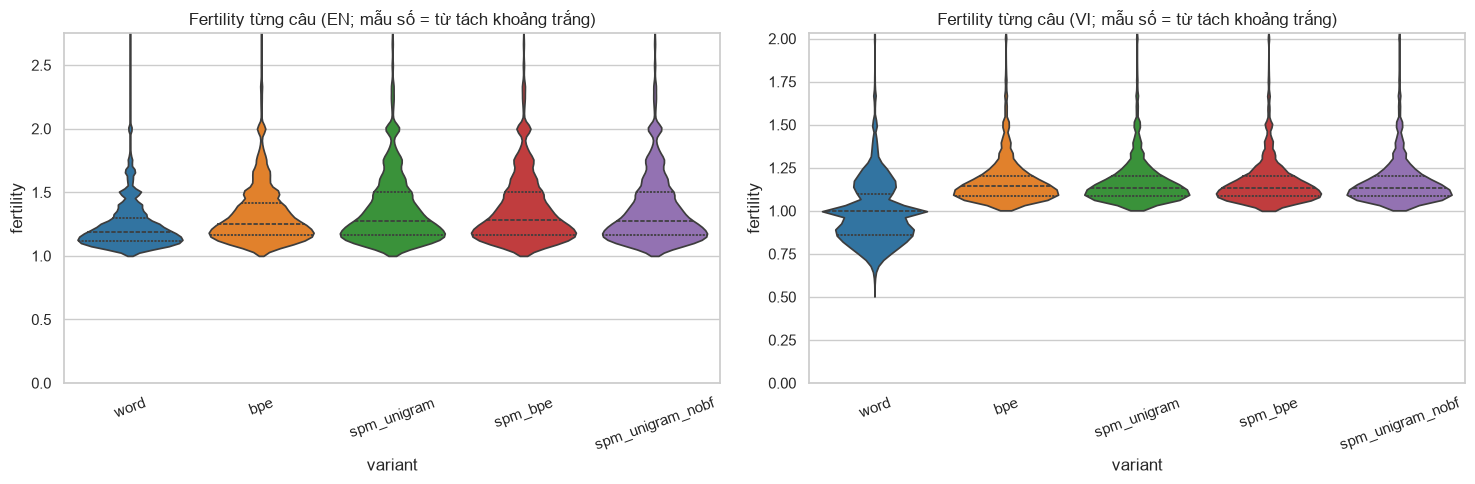

,,count,mean,std,min,50%,95%,99%,max
lang,variant,,,,,,,,
en,word,20191.0,1.238,0.177,1.0,1.188,1.600,1.833,3.5
vi,word,20191.0,0.986,0.181,0.5,1.000,1.273,1.500,4.0
en,bpe,20191.0,1.330,0.244,1.0,1.250,1.765,2.250,4.0
vi,bpe,20191.0,1.174,0.147,1.0,1.143,1.444,1.750,4.0
en,spm_unigram,20191.0,1.365,0.280,1.0,1.278,2.000,2.333,3.5
vi,spm_unigram,20191.0,1.168,0.142,1.0,1.133,1.429,1.733,4.0
en,spm_bpe,20191.0,1.370,0.282,1.0,1.286,2.000,2.333,4.0
vi,spm_bpe,20191.0,1.168,0.142,1.0,1.133,1.429,1.750,3.0
en,spm_unigram_nobf,20191.0,1.364,0.279,1.0,1.278,2.000,2.333,3.5


In [9]:
fl = pd.concat([pd.DataFrame({'variant': v, 'lang': l, 'fertility': d['ntok'] / d['nws']}) for (v, l), d in PER.items()])
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, l in zip(axes, LANGS):
    sub = fl[fl.lang == l]
    sns.violinplot(data=sub, x='variant', y='fertility', order=VARIANTS, palette=PAL, hue='variant', legend=False, cut=0, inner='quartile', ax=ax)
    ax.set_ylim(0, sub.fertility.quantile(0.995) * 1.1)
    ax.set_title(f'Fertility từng câu ({l.upper()}; mẫu số = từ tách khoảng trắng)'); ax.tick_params(axis='x', rotation=20)
savefig('fertility_violin.png')
fl.groupby(['lang', 'variant']).fertility.describe(percentiles=[.5, .95, .99]).loc[(slice(None), VARIANTS), :].round(3)

## 8. Độ dài chuỗi token

Độ dài chuỗi quyết định bộ nhớ và thời gian huấn luyện Transformer ($O(L^2)$ attention) và độ trễ khi sinh (autoregressive $O(L)$ bước). Ngoài giá trị trung bình, các phần trăm vượt 64/128/256 token cho biết bao nhiêu câu sẽ bị cắt nếu đặt `max_len` cố định. Tỉ số $\rho=L_{vi}/L_{en}$ cho biết độ lệch độ dài giữa nguồn và đích.

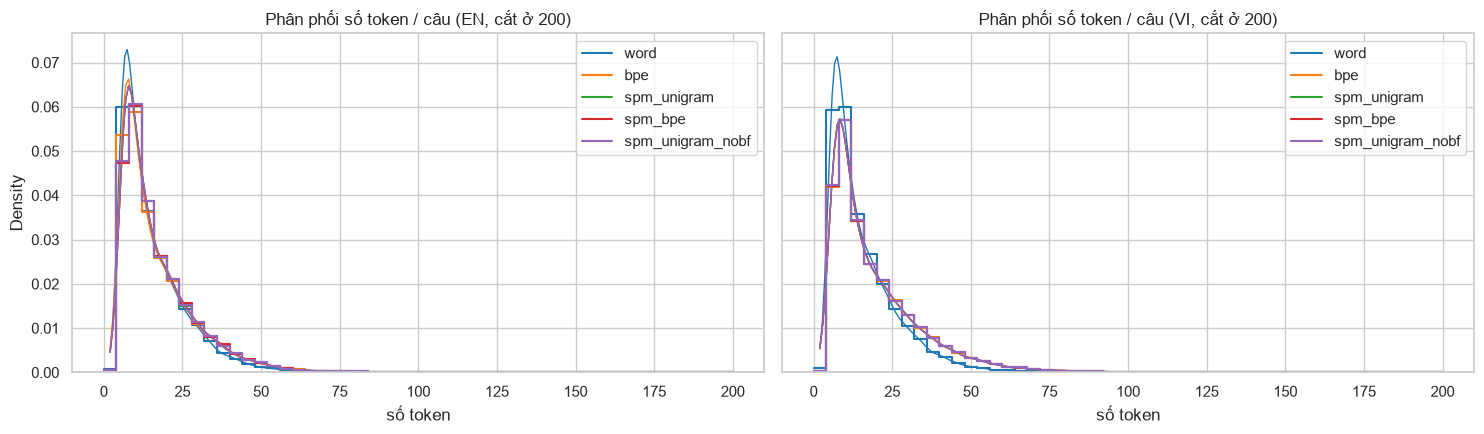

,variant,lang,L_mean,L_median,L_p95,L_p99,L_max,pct_gt64,pct_gt128,pct_gt256
0,word,en,15.44,12.0,36.0,53.1,223,0.48,0.02,0.00
1,bpe,en,16.82,13.0,41.0,61.0,284,0.81,0.05,0.00
2,spm_unigram,en,17.07,13.0,41.0,61.0,281,0.84,0.05,0.01
3,spm_bpe,en,17.14,13.0,41.0,62.0,281,0.81,0.05,0.01
4,spm_unigram_nobf,en,17.06,13.0,41.0,61.0,281,0.83,0.05,0.00
5,word,vi,15.69,12.0,37.0,55.0,219,0.52,0.03,0.00
6,bpe,vi,19.48,14.0,49.0,74.0,315,1.72,0.11,0.00
7,spm_unigram,vi,19.37,14.0,49.0,73.0,312,1.66,0.11,0.00
8,spm_bpe,vi,19.39,14.0,49.0,73.0,308,1.67,0.11,0.00
9,spm_unigram_nobf,vi,19.37,14.0,49.0,73.0,312,1.66,0.11,0.00


lang,en,vi,rho_vi_en
variant,,,
word,15.445,15.688,1.016
bpe,16.820,19.485,1.158
spm_unigram,17.074,19.371,1.135
spm_bpe,17.142,19.388,1.131
spm_unigram_nobf,17.059,19.365,1.135


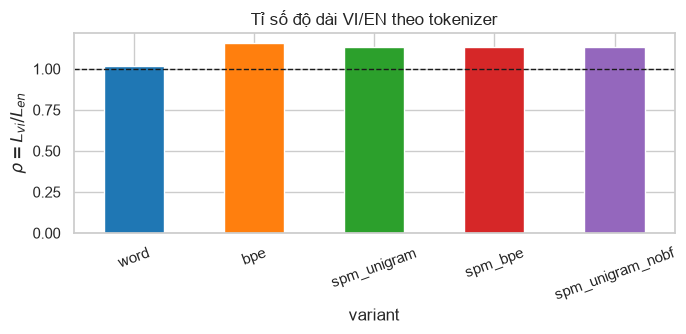

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, l in zip(axes, LANGS):
    for v in VARIANTS:
        x = PER[v, l]['ntok']
        sns.histplot(x[x <= 200], bins=np.arange(0, 201, 4), stat='density', element='step', fill=False, color=PAL[v], kde=True, label=v, ax=ax, line_kws={'lw': 1})
    ax.set_title(f'Phân phối số token / câu ({l.upper()}, cắt ở 200)'); ax.set_xlabel('số token'); ax.legend()
savefig('length_hist_kde.png')

len_tab = M_VALID[['variant', 'lang', 'L_mean', 'L_median', 'L_p95', 'L_p99', 'L_max', 'pct_gt64', 'pct_gt128', 'pct_gt256']]
display(len_tab.round(2))
ratio = M_VALID.pivot(index='variant', columns='lang', values='L_mean').loc[VARIANTS]
ratio['rho_vi_en'] = ratio['vi'] / ratio['en']
display(ratio.round(3))
ax = ratio.rho_vi_en.plot.bar(color=[PAL[v] for v in VARIANTS], figsize=(7, 3.5)); ax.axhline(1, c='k', ls='--', lw=1)
ax.set_ylabel(r'$\rho=L_{vi}/L_{en}$'); ax.set_title('Tỉ số độ dài VI/EN theo tokenizer'); plt.xticks(rotation=20)
savefig('length_ratio.png')

## 9. OOV

### 9.1 So sánh các biến thể
**Kỳ vọng:** byte-level BPE và SentencePiece có `byte_fallback` cho OOV $=0$ (mọi chuỗi biểu diễn được bằng byte). Chỉ word-level và `spm_unigram_nobf` mới có `<unk>`. Biểu đồ dưới dùng trục log vì chênh lệch rất lớn.

**Lưu ý khi đọc OOV (quan trọng):**
- OOV $=0$ của BPE byte-level và SentencePiece `byte_fallback` là **hệ quả của cách xây dựng** (mọi chuỗi đều phân rã được thành byte), *không phải* một phát hiện thực nghiệm; chỉ `word` và `spm_unigram_nobf` mới có OOV đo được.
- `n_types` **không so sánh được giữa các họ**: với word-level đó là type của token sau NLTK/PyVi (đã tách dấu câu, ghép âm tiết), với subword là type của từ tách bằng khoảng trắng. Vì vậy `oov_type` giữa các họ cũng chỉ mang tính tham khảo.
- Kích thước từ vựng word-level $=$ 4 token đặc biệt + $(V-4)$ từ, tức đã tính cả specials (các họ khác cũng tính specials trong $V$).

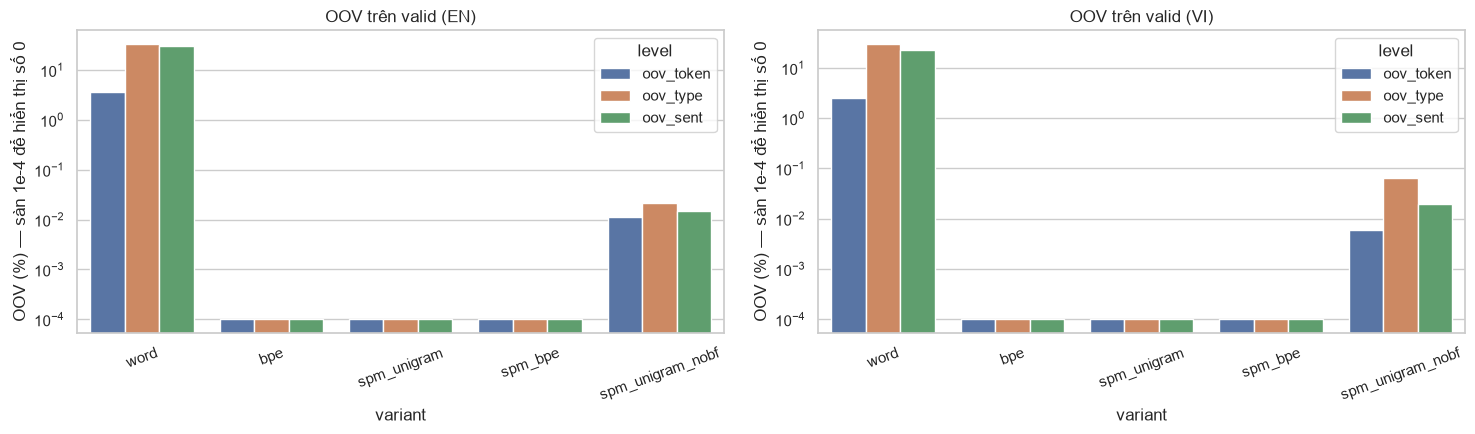

,level,oov_sent,oov_token,oov_type
lang,variant,,,
en,word,30.4096,3.5922,32.7277
vi,word,22.7180,2.4618,29.5514
en,bpe,0.0000,0.0000,0.0000
vi,bpe,0.0000,0.0000,0.0000
en,spm_unigram,0.0000,0.0000,0.0000
vi,spm_unigram,0.0000,0.0000,0.0000
en,spm_bpe,0.0000,0.0000,0.0000
vi,spm_bpe,0.0000,0.0000,0.0000
en,spm_unigram_nobf,0.0149,0.0110,0.0218


In [11]:
oo = M_VALID.melt(id_vars=['variant', 'lang'], value_vars=['oov_token', 'oov_type', 'oov_sent'], var_name='level', value_name='oov')
oo['oov_pct'] = 100 * oo.oov
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, l in zip(axes, LANGS):
    sub = oo[oo.lang == l].copy(); sub['oov_plot'] = sub.oov_pct.clip(lower=1e-4)
    sns.barplot(data=sub, x='variant', y='oov_plot', hue='level', order=VARIANTS, ax=ax)
    ax.set_yscale('log'); ax.set_ylabel('OOV (%) — sàn 1e-4 để hiển thị số 0'); ax.set_title(f'OOV trên valid ({l.upper()})'); ax.tick_params(axis='x', rotation=20)
savefig('oov_bar.png')
display(oo.pivot_table(index=['lang', 'variant'], columns='level', values='oov_pct').loc[(slice(None), VARIANTS), :].round(4))

### 9.2 Đường cong OOV theo kích thước từ vựng (word-level)
Với word-level, kích thước từ vựng $N$ là núm vặn chính đánh đổi giữa OOV và kích thước embedding/softmax. Ta dùng xếp hạng tần suất trên mẫu train: từ có $\text{rank}\ge N-4$ (trừ 4 token đặc biệt) bị đổi thành `<unk>`. Điểm "all" là toàn bộ từ vựng train, nên OOV còn lại chỉ là từ *chưa từng thấy* trong train.

### Hàm `word_oov_curve`
Với danh sách kích thước $N$, tính $\text{OOV}_{tok}(N)$ và $\text{OOV}_{type}(N)$ của word-level trên valid mà không cần dựng lại tokenizer.

,lang,N,label,oov_token,oov_type
0,en,8000,8000,0.0985,0.7023
1,en,16000,16000,0.0610,0.5088
2,en,32000,32000,0.0359,0.3273
3,en,64000,64000,0.0223,0.2062
4,en,128000,128000,0.0150,0.1394
5,en,340778,all,0.0100,0.0987
6,vi,8000,8000,0.0656,0.6318
7,vi,16000,16000,0.0390,0.4377
8,vi,32000,32000,0.0246,0.2955
9,vi,64000,64000,0.0175,0.2151


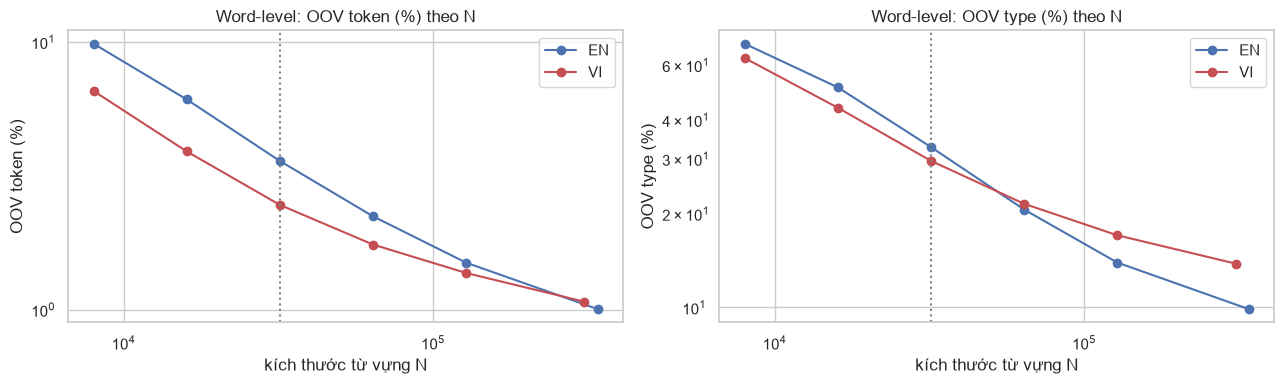

In [12]:
def word_oov_curve(lang, sizes):
    """OOV token/type của word-level trên valid theo kích thước vocab N (dùng rank tần suất trên train). 'all' = mọi từ train."""
    rank = {w: i for i, (w, _) in enumerate(WCOUNT[lang].most_common())}
    toks = [w for t in REG['word', lang]['tokenize'](EVAL['valid'][lang]) for w in t]
    r = np.array([rank.get(w, 10**12) for w in toks])
    ut = list(set(toks)); ru = np.array([rank.get(w, 10**12) for w in ut])
    out = []
    for n in sizes:
        thr = 10**12 if n == 'all' else n - len(SPECIALS)
        out.append(dict(lang=lang, N=len(rank) + len(SPECIALS) if n == 'all' else n, label=str(n), oov_token=(r >= thr).mean(), oov_type=(ru >= thr).mean()))
    return out

SIZES = [VOCAB_SIZE // 4, VOCAB_SIZE // 2, VOCAB_SIZE, 2 * VOCAB_SIZE, 4 * VOCAB_SIZE, 'all']
curve = pd.DataFrame([r for l in LANGS for r in word_oov_curve(l, SIZES)])
display(curve.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for l, c in zip(LANGS, ['C0', 'C3']):
    s = curve[curve.lang == l]
    axes[0].plot(s.N, 100 * s.oov_token, 'o-', c=c, label=l.upper()); axes[1].plot(s.N, 100 * s.oov_type, 'o-', c=c, label=l.upper())
for ax, t in zip(axes, ['OOV token (%)', 'OOV type (%)']):
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('kích thước từ vựng N'); ax.set_ylabel(t); ax.legend(); ax.set_title(f'Word-level: {t} theo N')
    ax.axvline(VOCAB_SIZE, c='gray', ls=':')
savefig('oov_vocab_curve.png')

### 9.3 Cái gì bị mất? Top-20 từ OOV phổ biến nhất (word-level, valid)
OOV không chỉ là con số; xem *loại* từ nào bị mất (tên riêng, số, từ hiếm, lỗi gõ) mới biết sửa bằng cách nào (copy mechanism, tách số, subword…). Phân loại nhanh theo hình thức: chứa chữ số / viết hoa đầu (tên riêng) / chữ thường / khác.

### Hàm `oov_kind`
Phân loại một từ OOV thành `number`, `Capitalized`, `lowercase` hoặc `other`.

In [13]:
def oov_kind(w):
    """Phân loại từ OOV: chứa chữ số -> 'number'; chữ cái đầu hoa -> 'Capitalized'; toàn chữ thường -> 'lowercase'; còn lại 'other'."""
    if any(c.isdigit() for c in w): return 'number'
    if w[:1].isupper(): return 'Capitalized'
    if w.replace('_', '').isalpha() and w == w.lower(): return 'lowercase'
    return 'other'

for l in LANGS:
    tk = REG['word', l]
    oc = Counter(w for t in tk['tokenize'](EVAL['valid'][l]) for w in t if w not in tk['stoi'])
    tot = sum(oc.values())
    print(f'=== {l.upper()}: {tot:,d} token OOV, {len(oc):,d} loại OOV ===')
    display(pd.DataFrame(oc.most_common(20), columns=['word', 'count']).T)
    kinds = Counter()
    for w, c in oc.items():
        kinds[oov_kind(w)] += c
    print('cơ cấu theo token OOV (%):', {k: round(100 * c / tot, 1) for k, c in kinds.most_common()})
    print('hapax trong train chiếm bao nhiêu loại từ:', f'{100 * sum(c == 1 for c in WCOUNT[l].values()) / len(WCOUNT[l]):.1f}%')

=== EN: 11,202 token OOV, 7,799 loại OOV ===


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
word,GoDaddy,☐,Subašić,Mallow,defectors,CISM,inosine,Uniq,Belov,CID,Wal-Mart,CPI,Shephard,Hewitt,Boulogne,meze,girly,Romney,Billancourt,Acemoglu
count,35,28,26,24,23,23,23,23,22,19,18,17,17,16,16,15,15,15,14,14


cơ cấu theo token OOV (%): {'Capitalized': 48.9, 'lowercase': 39.5, 'other': 6.2, 'number': 5.3}
hapax trong train chiếm bao nhiêu loại từ: 55.9%
=== VI: 7,798 token OOV, 5,467 loại OOV ===


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
word,Bolt,GoDaddy,☐,Subašić,Mallow,inosine,bụt,Thú_Vật,Uniq,Belov,CISM,CID,Boxer,Shephard,meze,Billancourt,Talos,Hewitt,Kanza,swing
count,51,34,28,26,24,23,23,22,21,20,18,17,16,16,15,14,13,13,13,13


cơ cấu theo token OOV (%): {'Capitalized': 70.7, 'lowercase': 24.4, 'number': 4.0, 'other': 0.9}
hapax trong train chiếm bao nhiêu loại từ: 61.5%


## 10. Tốc độ mã hóa

Tokenizer chậm làm nghẽn pipeline dữ liệu (nhất là khi tokenization online). Đo cùng một tập câu valid cho mọi tokenizer, 1 lượt warm-up + trung vị 3 lượt đo (định nghĩa 6.4). Hai chế độ: *loop* (từng câu trong vòng lặp Python; word-level thì tuần tự 1 tiến trình) và *batch* (HF `encode_batch` chạy Rust đa luồng, `sp.encode(list)`, word-level qua `multiprocessing.Pool`). Ghi lại số CPU để so sánh có ý nghĩa.

**Song song hóa theo từng họ (khác nhau!):** HF `encode_batch` chạy Rust đa luồng (rayon, mọi lõi); SentencePiece `encode(list)` dùng `num_threads` $=\min(16,\text{cpu})$; word-level dùng `multiprocessing.Pool` 12 tiến trình (spawn). Chế độ *loop* thì cả ba đều chạy 1 luồng/1 tiến trình. **Vì vậy so sánh công bằng giữa các họ là số liệu *loop* (đơn luồng)**; số *batch* phản ánh thông lượng thực dùng nhưng bị lệch bởi mức song song khác nhau.

### Hàm `bench`
Chạy `fn(texts)` 1 lần warm-up rồi 3 lần có đo giờ; trả về (thời gian trung vị, tổng số token).

speed: 100%|██████████| 10/10 [00:34<00:00,  3.49s/it]

CPU = 20, SPM threads = 16, câu đo = 20,191


,variant,lang,mode,sec,sent_per_s,tok_per_s
0,word,en,loop,1.6,12375.0,191126.7
1,word,en,batch,0.2,83283.3,1286273.8
2,bpe,en,loop,0.6,35452.3,596302.0
3,bpe,en,batch,0.1,213452.2,3590228.0
4,spm_unigram,en,loop,0.1,143866.5,2456446.7
5,spm_unigram,en,batch,0.0,800309.2,13664869.8
6,spm_bpe,en,loop,0.4,51305.5,879493.0
7,spm_bpe,en,batch,0.0,481880.8,8260541.7
8,spm_unigram_nobf,en,loop,0.1,143584.8,2449433.1
9,spm_unigram_nobf,en,batch,0.0,809878.5,13815826.9


mode,batch,loop,pool_speedup
lang,,,
en,83283.32,12375.02,6.73
vi,37320.58,6783.51,5.50


HF encode_batch: Rust đa luồng; SPM: num_threads=16 (=min(16,cpu=20)); word-level: Pool 12 tiến trình (spawn)
Tỉ số tốc độ so với word-level (loop = đơn luồng, so sánh công bằng):


,bpe/word (loop),spm_unigram/word (loop),spm_bpe/word (loop),bpe/word (batch),spm_unigram/word (batch),spm_bpe/word (batch)
lang,,,,,,
en,2.86,11.63,4.15,2.56,9.61,5.79
vi,4.40,19.66,8.21,3.88,17.68,13.09


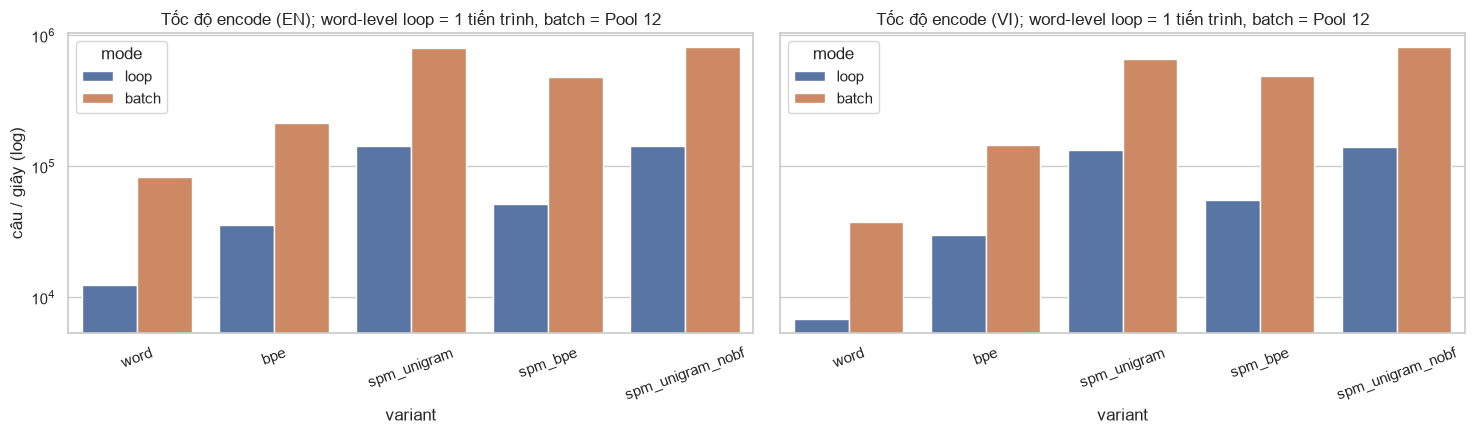

In [14]:
def bench(fn, texts, reps=3):
    """Warm-up 1 lượt rồi đo `reps` lượt; trả về (trung vị giây, tổng số token của lượt cuối)."""
    fn(texts)
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); out = fn(texts); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), sum(len(x) for x in out)

srows = []
for (v, l), tk in tqdm(REG.items(), desc='speed'):
    tx = EVAL['valid'][l]
    for mode in ['enc_loop', 'enc_batch']:
        sec, nt = bench(tk[mode], tx)
        srows.append(dict(variant=v, lang=l, mode=mode.replace('enc_', ''), sec=sec, sent_per_s=len(tx) / sec, tok_per_s=nt / sec))
SPEED = pd.DataFrame(srows)
print(f'CPU = {N_PROC}, SPM threads = {SPM_THREADS}, câu đo = {len(EVAL["valid"]["en"]):,d}')
display(SPEED.round(1))
sp_ = SPEED[SPEED.variant == 'word'].pivot(index='lang', columns='mode', values='sent_per_s')
sp_['pool_speedup'] = sp_['batch'] / sp_['loop']
display(sp_.round(2))
PAR_NOTE = f'HF encode_batch: Rust đa luồng; SPM: num_threads={SPM_THREADS} (=min(16,cpu={N_PROC})); word-level: Pool {N_POOL} tiến trình (spawn)'
print(PAR_NOTE)
LOOP = SPEED[SPEED['mode'] == 'loop'].pivot(index='lang', columns='variant', values='sent_per_s')
BATCH = SPEED[SPEED['mode'] == 'batch'].pivot(index='lang', columns='variant', values='sent_per_s')
FAIR = pd.DataFrame({f'{a}/word ({m})': T[a] / T['word'] for m, T in [('loop', LOOP), ('batch', BATCH)] for a in ['bpe', 'spm_unigram', 'spm_bpe']})
print('Tỉ số tốc độ so với word-level (loop = đơn luồng, so sánh công bằng):')
display(FAIR.round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, l in zip(axes, LANGS):
    sub = SPEED[SPEED.lang == l]
    sns.barplot(data=sub, x='variant', y='sent_per_s', hue='mode', order=VARIANTS, ax=ax)
    ax.set_yscale('log'); ax.set_title(f'Tốc độ encode ({l.upper()}); word-level loop = 1 tiến trình, batch = Pool {N_POOL}'); ax.set_ylabel('câu / giây (log)'); ax.tick_params(axis='x', rotation=20)
savefig('speed_bar.png')

## 11. Round trip: decode(encode(x)) = x ?

Dịch máy phải *giải mã lại* thành văn bản; nếu tokenizer mất thông tin (khoảng trắng, dấu nháy, ký tự lạ, `<unk>`) thì bản dịch chắc chắn lệch dù mô hình hoàn hảo. Đo tỉ lệ $R$ (6.5) trên 5k câu valid chọn ngẫu nhiên có seed và phân loại nguyên nhân: `has_unk`, `spacing_only` (khác nhau chỉ ở khoảng trắng), `other_normalization` (SentencePiece chuẩn hóa NFKC; NLTK đổi `"` thành `` `` ``/`''`…).

Word-level decode bằng cách nối token bằng dấu cách (và đổi `_` thành dấu cách với VI), tức là không có bước "detokenize" thông minh; thêm detokenizer sẽ cải thiện nhưng không bao giờ khôi phục được `<unk>`.

### Hàm `roundtrip`
Mã hóa rồi giải mã các câu, trả về (tỉ lệ khớp tuyệt đối, Counter phân loại, ví dụ lệch do chuẩn hóa, Counter ký tự mất/đổi).

In [15]:
def roundtrip(tk, texts):
    """Trả về (R, Counter các loại kết quả, list (gốc, giải mã) lệch do chuẩn hóa, Counter ký tự có trong gốc nhưng mất ở bản giải mã)."""
    ids = tk['enc_batch'](texts); dec = tk['dec'](ids)
    cats, others = Counter(), []
    for s, d, i in zip(texts, dec, ids):
        if d == s: cats['exact'] += 1
        elif UNK_ID in i: cats['has_unk'] += 1
        elif re.sub(r'\s+', '', d) == re.sub(r'\s+', '', s): cats['spacing_only'] += 1
        else: cats['other_normalization'] += 1; others.append((s, d))
    lost = Counter(c for s, d in others for c in set(s) - set(d))
    return cats['exact'] / len(texts), cats, others, lost

rt_idx = np.sort(np.random.default_rng(SEED + 2).choice(len(EVAL['valid']['en']), min(N_RT, len(EVAL['valid']['en'])), replace=False))
RT, rrows = {}, []
for (v, l), tk in tqdm(REG.items(), desc='roundtrip'):
    r, cats, others, lost = roundtrip(tk, [EVAL['valid'][l][i] for i in rt_idx])
    RT[v, l] = (others, lost)
    rrows.append(dict(variant=v, lang=l, rt_exact=r, **{k: cats.get(k, 0) for k in ['exact', 'has_unk', 'spacing_only', 'other_normalization']}))
RTDF = pd.DataFrame(rrows)
display(RTDF.round(4))
for (v, l) in [('word', 'en'), ('word', 'vi'), ('spm_unigram', 'en'), ('spm_unigram', 'vi'), ('bpe', 'vi')]:
    others, lost = RT[v, l]
    print(f'--- {v}/{l}: ký tự bị mất/đổi nhiều nhất = {lost.most_common(8)}')
    for s, d in others[:2]:
        print('   gốc :', s[:140]); print('   giải:', d[:140])

roundtrip: 100%|██████████| 10/10 [00:00<00:00, 15.62it/s]


,variant,lang,rt_exact,exact,has_unk,spacing_only,other_normalization
0,word,en,0.0010,5,1557,3333,105
1,bpe,en,1.0000,5000,0,0,0
2,spm_unigram,en,0.9996,4998,0,0,2
3,spm_bpe,en,0.9996,4998,0,0,2
4,spm_unigram_nobf,en,0.9992,4996,2,0,2
5,word,vi,0.0146,73,1094,3833,0
6,bpe,vi,1.0000,5000,0,0,0
7,spm_unigram,vi,0.9982,4991,0,0,9
8,spm_bpe,vi,0.9982,4991,0,0,9
9,spm_unigram_nobf,vi,0.9978,4989,2,0,9


--- word/en: ký tự bị mất/đổi nhiều nhất = [('"', 105)]
   gốc : In December, the police arrested prominent rights campaigner Nguyen Van Dai and charged him with "conducting propaganda against the state" a
   giải: In December , the police arrested prominent rights campaigner Nguyen Van Dai and charged him with `` conducting propaganda against the state
   gốc : "It should not matter if someone is protesting in favor or against the government's preferred position.
   giải: `` It should not matter if someone is protesting in favor or against the government 's preferred position .
--- word/vi: ký tự bị mất/đổi nhiều nhất = []
--- spm_unigram/en: ký tự bị mất/đổi nhiều nhất = [('º', 1), ('…', 1)]
   gốc : Bake at 375ºF for 30 to 35 minutes.
   giải: Bake at 375oF for 30 to 35 minutes.
   gốc : "An unwillingness to support a seemingly strategic company … raises questions on the health of the public enterprise sector at large, and th
   giải: "An unwillingness to support a seemingly strateg

## 12. Khám phá bổ sung

### 12.1 Luật Zipf: tần suất theo hạng (log-log)
Phân phối tần suất của đơn vị token quyết định mức "thưa" của dữ liệu cho embedding. Zipf: $f(r)\propto r^{-\alpha}$. Word-level có đuôi dài (nhiều loại từ hiếm) $\Rightarrow$ nhiều embedding chỉ được thấy vài lần; token con từ có phân phối phẳng hơn và vocab cố định nên không có đuôi vô hạn. Từ vựng word-level lấy từ toàn mẫu 1M câu; token con từ đếm trên `ZIPF_N` câu đầu của mẫu (đủ để thấy hình dạng).

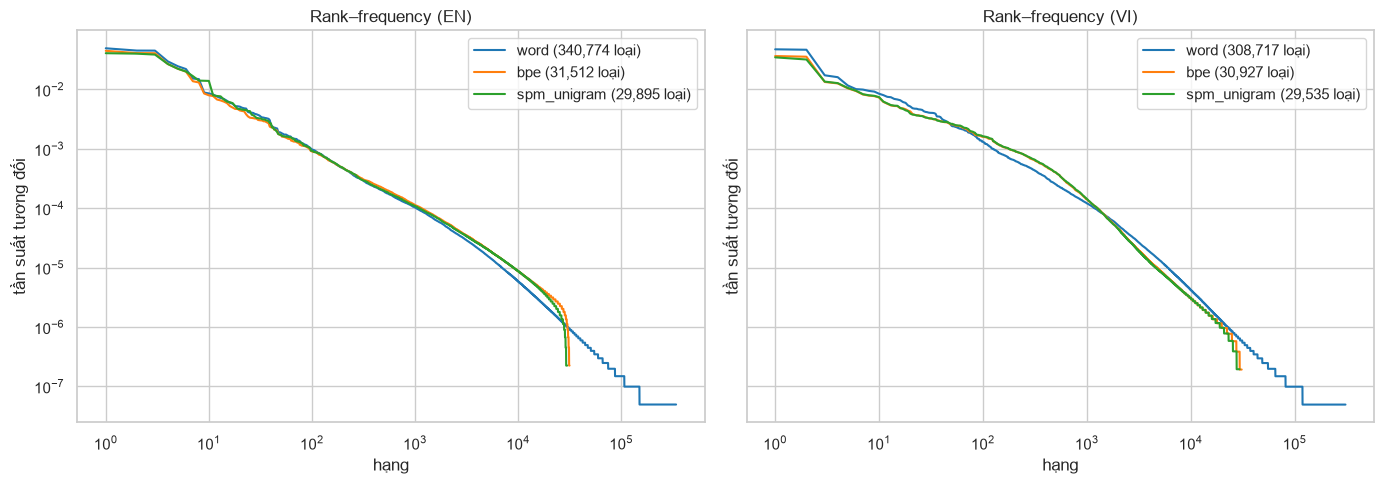

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ZIPF = {}
for ax, l in zip(axes, LANGS):
    for v in ['word', 'bpe', 'spm_unigram']:
        if v == 'word':
            f = np.array(sorted(WCOUNT[l].values(), reverse=True))
        else:
            cnt = Counter(itertools.chain.from_iterable(REG[v, l]['enc_batch'](TRAIN[l][:ZIPF_N])))
            f = np.array(sorted(cnt.values(), reverse=True))
        ZIPF[v, l] = f
        ax.loglog(np.arange(1, len(f) + 1), f / f.sum(), label=f'{v} ({len(f):,d} loại)', c=PAL[v])
    ax.set_title(f'Rank–frequency ({l.upper()})'); ax.set_xlabel('hạng'); ax.set_ylabel('tần suất tương đối'); ax.legend()
savefig('zipf.png')

### 12.2 Phân phối độ dài mục từ (byte UTF-8) trong từ vựng đã học
Cho biết tokenizer học ra đơn vị "to" hay "nhỏ". Mục từ dài $\Rightarrow$ chuỗi ngắn hơn nhưng kém khái quát; mục từ rất ngắn (1–2 byte) chiếm nhiều $\Rightarrow$ chuỗi dài. Đơn vị là **byte** để so sánh công bằng giữa HF byte-level, SPM và word-level (ký tự có dấu tiếng Việt chiếm 2–3 byte).

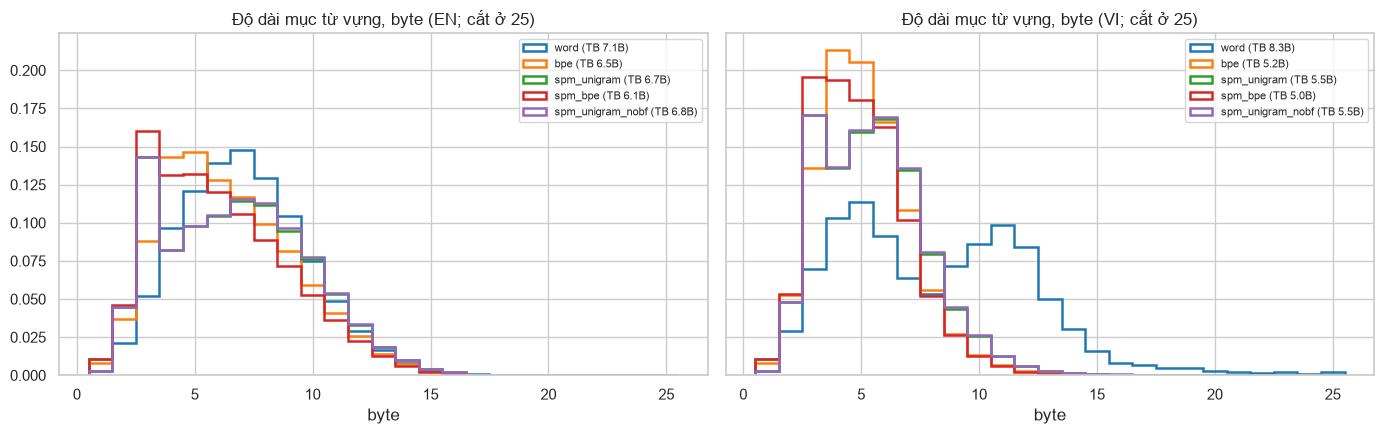

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, l in zip(axes, LANGS):
    for v in VARIANTS:
        b = np.array(REG[v, l]['tok_bytes'])
        ax.hist(np.clip(b, 0, 25), bins=np.arange(0.5, 26.5, 1), density=True, histtype='step', lw=1.8, color=PAL[v], label=f'{v} (TB {b.mean():.1f}B)')
    ax.set_title(f'Độ dài mục từ vựng, byte ({l.upper()}; cắt ở 25)'); ax.set_xlabel('byte'); ax.legend(fontsize=8)
savefig('vocab_token_length.png')

### 12.3 Từ vựng chung EN/VI (cho quyết định joint vs separate vocab)
Độ chồng lấn từ vựng chỉ là một *giả thuyết* cho quyết định joint vs separate: chia sẻ ít thì vocab chung không tiết kiệm được nhiều, chia sẻ nhiều thì có thể dùng chung embedding (tied). Giả thuyết này được thử trực tiếp trên fertility/độ dài ở mục 12.7. Đếm số mục từ chung (bỏ token đặc biệt) và chỉ số Jaccard:
$$J=\frac{|V_{en}\cap V_{vi}|}{|V_{en}\cup V_{vi}|}$$
Với BPE byte-level, "chung" nghĩa là cùng chuỗi byte (ví dụ các token ASCII, số, dấu câu, tên riêng; và cả các mảnh byte UTF-8 của chữ có dấu nếu chúng xuất hiện ở EN, ví dụ từ mượn).

,variant,V_en,V_vi,shared,union,jaccard,shared_pct_of_en
0,word,31996,31996,7487,56505,0.133,23.400
1,bpe,31996,31996,11059,52933,0.209,34.564
2,spm_unigram,31996,31996,13366,50626,0.264,41.774
3,spm_bpe,31996,31996,12968,51024,0.254,40.530


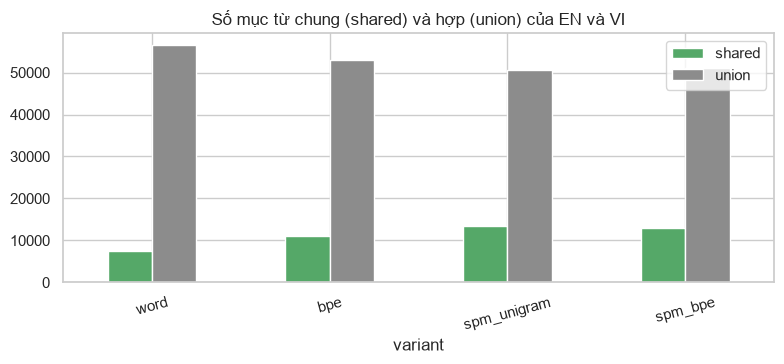

BPE: 15 mục chung dài nhất: [':................................................................', '................................................................', ' …………………………………………', '................................', ' ……………………', '........................', '……………………', ' ………………', '………………', ' Pharmaceuticals', '................', '----------------', ' Communications', ' Constantinople', ' corticosteroid']


In [18]:
ov = []
for v in ['word', 'bpe', 'spm_unigram', 'spm_bpe']:
    a, b = set(REG[v, 'en']['vocab']), set(REG[v, 'vi']['vocab'])
    ov.append(dict(variant=v, V_en=len(a), V_vi=len(b), shared=len(a & b), union=len(a | b), jaccard=len(a & b) / len(a | b), shared_pct_of_en=100 * len(a & b) / len(a)))
OVL = pd.DataFrame(ov)
display(OVL.round(3))
ax = OVL.set_index('variant')[['shared', 'union']].plot.bar(figsize=(8, 3.8), color=['C2', 'C7'])
ax.set_title('Số mục từ chung (shared) và hợp (union) của EN và VI'); plt.xticks(rotation=15)
savefig('vocab_overlap.png')
bpe_sh = sorted(set(REG['bpe', 'en']['vocab']) & set(REG['bpe', 'vi']['vocab']), key=len, reverse=True)
print('BPE: 15 mục chung dài nhất:', [bl_decode(t) for t in bpe_sh[:15]])

### 12.4 Số token theo số từ trong câu (scatter, 5k câu)
Fertility trung bình là *độ dốc* của quan hệ $|t(s)|\approx F\cdot w(s)$. Scatter cho thấy độ dốc có đồng đều theo độ dài câu hay chỉ do vài câu ngoại lai. Mỗi panel ghi độ dốc hồi quy tuyến tính qua gốc.

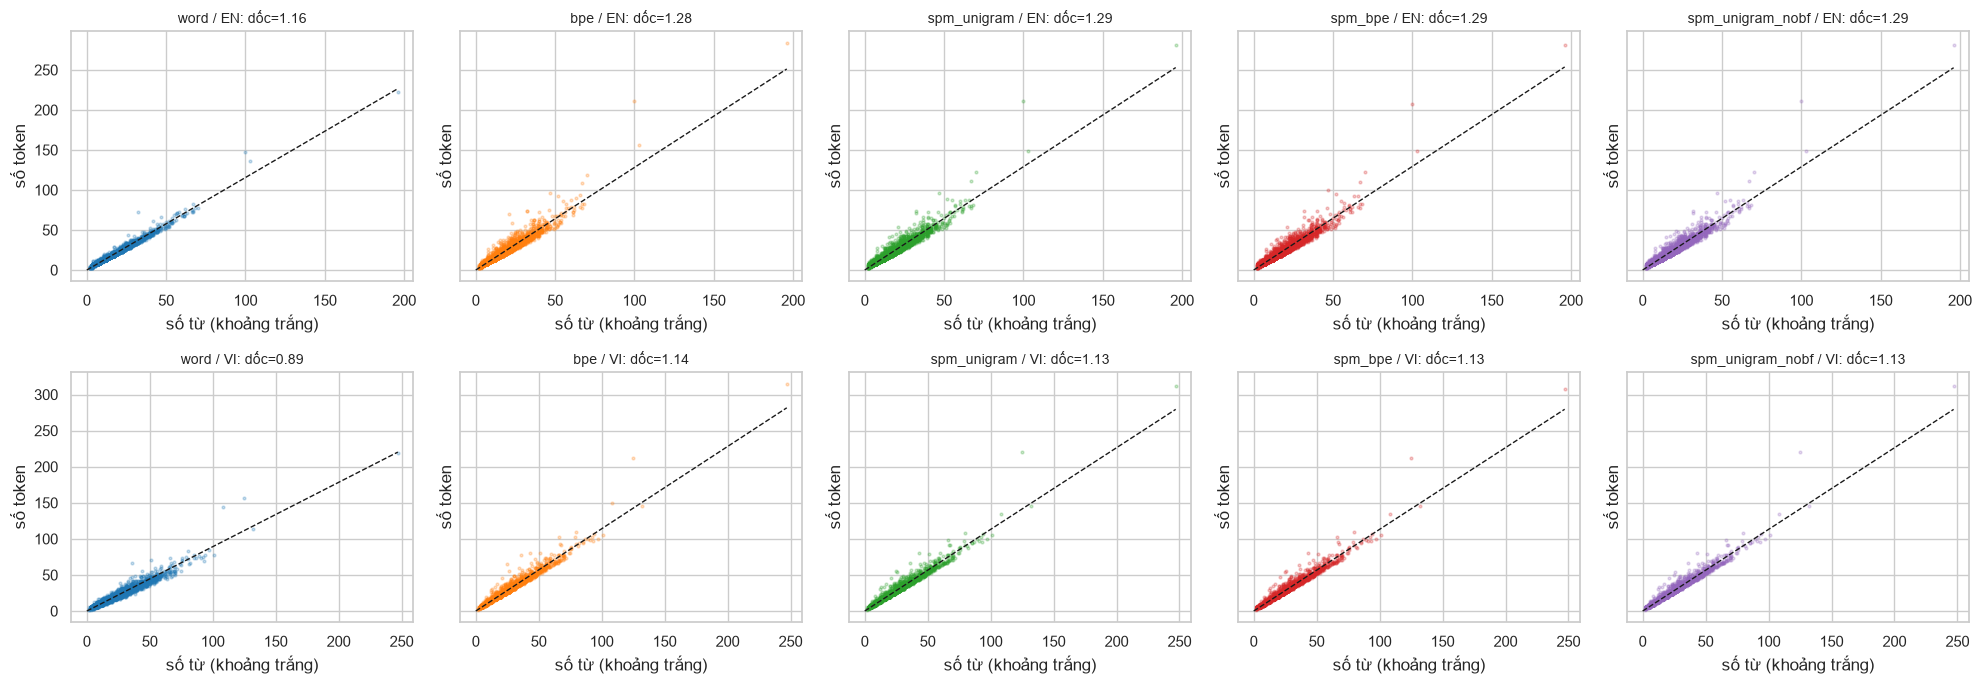

In [19]:
sc_idx = np.random.default_rng(SEED + 3).choice(len(EVAL['valid']['en']), min(N_SCATTER, len(EVAL['valid']['en'])), replace=False)
fig, axes = plt.subplots(2, len(VARIANTS), figsize=(4 * len(VARIANTS), 7), sharex='row', sharey='row')
for i, l in enumerate(LANGS):
    for j, v in enumerate(VARIANTS):
        x, y = PER[v, l]['nws'][sc_idx], PER[v, l]['ntok'][sc_idx]
        axes[i, j].scatter(x, y, s=4, alpha=.25, color=PAL[v])
        slope = (x * y).sum() / (x * x).sum()
        axes[i, j].plot([0, x.max()], [0, slope * x.max()], 'k--', lw=1)
        axes[i, j].set_title(f'{v} / {l.upper()}: dốc={slope:.2f}', fontsize=10); axes[i, j].set_xlabel('số từ (khoảng trắng)'); axes[i, j].set_ylabel('số token')
savefig('scatter_tokens_vs_words.png')

### 12.5 Quét kích thước từ vựng BPE: fertility theo $V$
Cho biết lợi ích biên của việc tăng $V$: mỗi lần nhân đôi $V$ làm giảm bao nhiêu token/từ. So với chi phí: ma trận embedding/softmax tăng tuyến tính theo $V$.

,lang,V,fert_ws,chars_per_token
0,en,8000,1.478,3.791
1,en,16000,1.360,4.120
2,en,32000,1.285,4.359
3,vi,8000,1.194,3.700
4,vi,16000,1.163,3.797
5,vi,32000,1.145,3.856


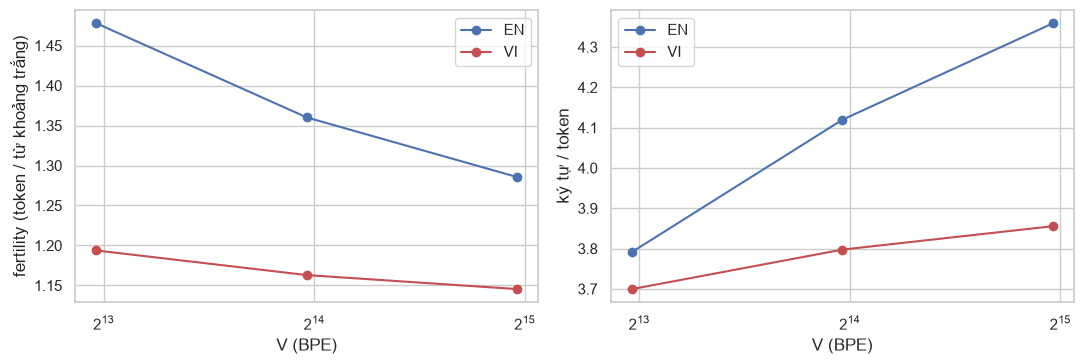

In [20]:
sw = []
for (l, s), t in BPE.items():
    tx = EVAL['valid'][l]
    nt = sum(len(e.ids) for e in t.encode_batch(tx))
    sw.append(dict(lang=l, V=s, fert_ws=nt / sum(len(x.split()) for x in tx), chars_per_token=sum(map(len, tx)) / nt))
SWEEP = pd.DataFrame(sw)
display(SWEEP.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for l, c in zip(LANGS, ['C0', 'C3']):
    s = SWEEP[SWEEP.lang == l]
    axes[0].plot(s.V, s.fert_ws, 'o-', c=c, label=l.upper()); axes[1].plot(s.V, s.chars_per_token, 'o-', c=c, label=l.upper())
for ax, t in zip(axes, ['fertility (token / từ khoảng trắng)', 'ký tự / token']):
    ax.set_xscale('log', base=2); ax.set_xlabel('V (BPE)'); ax.set_ylabel(t); ax.legend()
savefig('bpe_vocab_sweep.png')

### 12.6 Cùng một câu, các tokenizer tách khác nhau thế nào?
Số liệu tổng hợp che giấu hành vi cụ thể. 10 câu valid cố định (seed): 3 câu chọn theo tiêu chí (câu VI dài nhất dưới 300 ký tự; câu có nhiều chữ số nhất; câu có nhiều từ viết hoa nhất) và 7 câu ngẫu nhiên (VI luôn có dấu). Với BPE, token hiển thị sau khi giải mã byte (mảnh byte UTF-8 dở dang hiện `�`); `▁` là ký hiệu khoảng trắng của SentencePiece; `_` nối âm tiết trong từ ghép PyVi.

In [21]:
en_v, vi_v = EVAL['valid']['en'], EVAL['valid']['vi']
cand = [i for i in range(len(vi_v)) if len(vi_v[i]) <= 300]
pick = [max(cand, key=lambda i: len(vi_v[i])),
        max((i for i in cand if len(en_v[i]) <= 200), key=lambda i: sum(c.isdigit() for c in en_v[i])),
        max((i for i in cand if len(en_v[i]) <= 200), key=lambda i: sum(w[:1].isupper() for w in en_v[i].split()))]
rs = np.random.default_rng(SEED + 4)
while len(pick) < 10:
    i = int(rs.integers(len(en_v)))
    if i not in pick and 40 <= len(en_v[i]) <= 200: pick.append(i)
SEG = []
for k, i in enumerate(pick):
    print(f'\n#{k} (valid[{i}])\n EN: {en_v[i]}\n VI: {vi_v[i]}')
    for l in LANGS:
        for v in VARIANTS:
            p = REG[v, l]['pieces']([en_v, vi_v][l == 'vi'][i])
            SEG.append(dict(sent=k, lang=l, variant=v, n_tokens=len(p), tokens=' | '.join(p)))
            print(f'  {l}/{v:17s} n={len(p):3d}: {" | ".join(p)[:420]}')
pd.DataFrame(SEG).to_csv(RES_DIR / 'segmentation_examples.csv', index=False, encoding='utf-8-sig')


#0 (valid[12232])
 EN: The Eclipse Foundation is considered a "third generation" open-source organization, and is home to Jakarta EE, and over 350 open source projects, including runtimes, tools, and frameworks for a wide range of technology domains such as the Internet of Things (IoT), Automotive, Geospatial, Systems Engineering, and many others.
 VI: Eclipse Foundation được coi là một tổ chức nguồn mở "thế hệ thứ ba" và là nhà của Jakarta EE, và hơn 350 dự án nguồn mở khác, bao gồm các runtimes, công cụ, và frameworks cho một loạt các lĩnh vực công nghệ như Internet of Things (IoT), Automotive, Geospatial, Systems Engineering, và nhiều thứ khác.
  en/word              n= 62: The | Eclipse | Foundation | is | considered | a | `` | third | generation | '' | open-source | organization | , | and | is | home | to | Jakarta | EE | , | and | over | 350 | open | source | projects | , | including | runtimes | , | tools | , | and | frameworks | for | a | wide | range | of | technology | domai

### 12.7 Thử nghiệm joint vs separate vocab (fertility và độ dài)
Mục 12.3 chỉ đo độ chồng lấn. Ở đây ta *thử trực tiếp* giả thuyết "vocab chung có thể dùng được": huấn luyện **một** SentencePiece unigram (`byte_fallback`, 32k) và **một** ByteLevelBPE (32k) trên văn bản EN+VI ghép lại (cùng mẫu train, 2 × số câu), rồi so fertility $F$, ký tự/token và độ dài $L$ theo từng ngôn ngữ với hai vocab riêng 32k/ngôn ngữ trên cùng tập valid.

**Chú ý ngân sách:** vocab chung có 32k mục cho cả hai ngôn ngữ, còn separate có 32k *mỗi* ngôn ngữ (tổng 64k), nên đây là so sánh "cùng $V$ cho mỗi bộ tokenizer", không phải cùng tổng tham số embedding. Chỉ đo fertility/độ dài, **không** đo chất lượng dịch.

,algo,vocab,lang,vocab_size,fert_ws,chars_per_token,L_mean,L_p95,n_unk,fert_vs_separate_pct
0,bpe,joint,en,32000,1.3064,4.2890,17.0934,42.0,0,1.6266
1,bpe,separate,en,32000,1.2855,4.3587,16.8198,41.0,0,0.0000
2,bpe,joint,vi,32000,1.1599,3.8074,19.7314,50.0,0,1.2651
3,bpe,separate,vi,32000,1.1455,3.8556,19.4849,49.0,0,0.0000
4,spm_unigram,joint,en,32000,1.3266,4.2237,17.3577,42.0,0,1.6586
5,spm_unigram,separate,en,32000,1.3049,4.2937,17.0745,41.0,0,0.0000
6,spm_unigram,joint,vi,32000,1.1525,3.8319,19.6054,49.0,0,1.2086
7,spm_unigram,separate,vi,32000,1.1388,3.8782,19.3713,49.0,0,0.0000


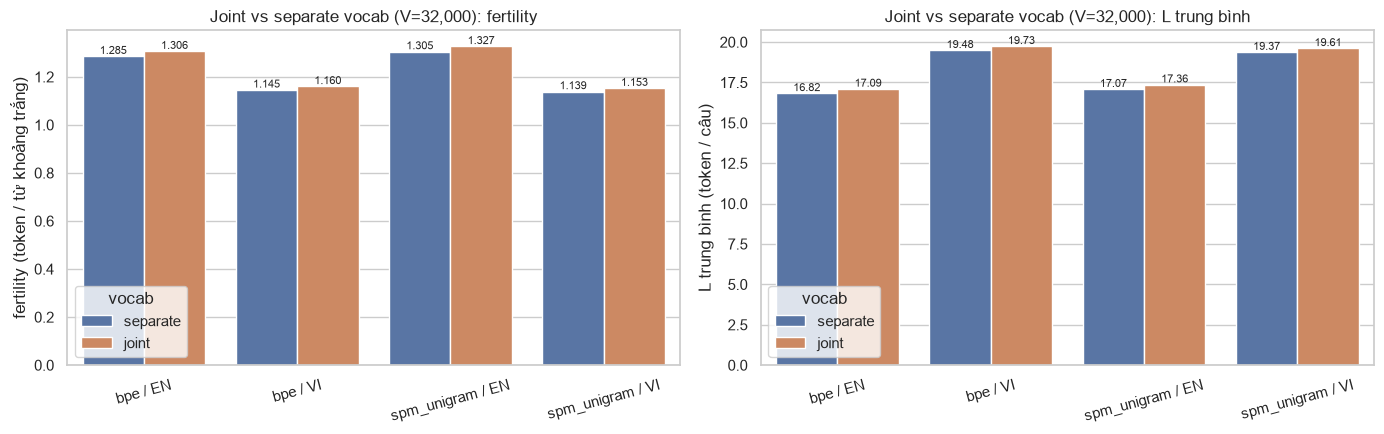

In [22]:
JOINT_JOB = TOK_DIR / 'spm_unigram_joint'
JOINT_BPE_F = TOK_DIR / 'bpe_joint' / 'tokenizer.json'
JOINT_TXT = INTERIM / f'spm_train_joint{sfx}.txt'
if not (REUSE and JOINT_JOB.with_suffix('.model').exists()):
    if not (REUSE and JOINT_TXT.exists()):
        JOINT_TXT.write_text('\n'.join(TRAIN['en'] + TRAIN['vi']) + '\n', encoding='utf-8')   # EN rồi VI; SPM tự xáo (shuffle_input_sentence)
    t0 = time.perf_counter()
    spm.SentencePieceTrainer.train(
        input=str(JOINT_TXT), model_prefix=str(JOINT_JOB), vocab_size=VOCAB_SIZE, model_type='unigram',
        character_coverage=1.0, byte_fallback=True, input_sentence_size=2 * N_TRAIN_SENT, shuffle_input_sentence=True,
        num_threads=SPM_THREADS, pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        pad_piece='<pad>', unk_piece='<unk>', bos_piece='<bos>', eos_piece='<eos>', hard_vocab_limit=False, minloglevel=2)
    TIMES['train_joint_spm_unigram'] = time.perf_counter() - t0
if not (REUSE and JOINT_BPE_F.exists()):
    JOINT_BPE_F.parent.mkdir(parents=True, exist_ok=True)
    t0 = time.perf_counter()
    tkj = ByteLevelBPETokenizer()
    tkj.train_from_iterator(TRAIN['en'] + TRAIN['vi'], vocab_size=VOCAB_SIZE, min_frequency=2, special_tokens=SPECIALS, show_progress=False)
    tkj.save_model(str(JOINT_BPE_F.parent)); tkj.save(str(JOINT_BPE_F))
    TIMES['train_joint_bpe'] = time.perf_counter() - t0
TIMES_F.write_text(json.dumps(TIMES, indent=1))
sp_j = spm.SentencePieceProcessor(model_file=str(JOINT_JOB.with_suffix('.model')))
bpe_j = Tokenizer.from_file(str(JOINT_BPE_F))
JENC = {'spm_unigram': (sp_j.get_piece_size(), lambda tx: sp_j.encode(tx)),
        'bpe': (bpe_j.get_vocab_size(), lambda tx: [e.ids for e in bpe_j.encode_batch(tx)])}

jrows = []
for algo, (vsz, enc) in JENC.items():
    for l in LANGS:
        tx = EVAL['valid'][l]; ids = enc(tx)
        ntok = np.array([len(x) for x in ids]); nws = np.array([len(s.split()) for s in tx])
        jrows.append(dict(algo=algo, vocab='joint', lang=l, vocab_size=vsz, fert_ws=ntok.sum() / nws.sum(),
                          chars_per_token=sum(map(len, tx)) / ntok.sum(), L_mean=ntok.mean(), L_p95=np.percentile(ntok, 95),
                          n_unk=int(sum(x.count(UNK_ID) for x in ids))))
sep = M_VALID[M_VALID.variant.isin(JENC)].assign(algo=lambda d: d.variant, vocab='separate')[['algo', 'vocab', 'lang', 'vocab_size', 'fert_ws', 'chars_per_token', 'L_mean', 'L_p95', 'n_unk']]
JOINT = pd.concat([sep, pd.DataFrame(jrows)], ignore_index=True)
base = JOINT[JOINT.vocab == 'separate'].set_index(['algo', 'lang'])
JOINT['fert_vs_separate_pct'] = [100 * (r.fert_ws / base.loc[(r.algo, r.lang), 'fert_ws'] - 1) for r in JOINT.itertuples()]
JOINT = JOINT.sort_values(['algo', 'lang', 'vocab']).reset_index(drop=True)
assert (JOINT[JOINT.algo == 'bpe'].n_unk == 0).all() and JOINT.fert_ws.notna().all()
display(JOINT.round(4))
JOINT.round(6).to_csv(RES_DIR / 'joint_vs_separate.csv', index=False)

JOINT['key'] = JOINT.algo + ' / ' + JOINT.lang.str.upper()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (col, t) in zip(axes, [('fert_ws', 'fertility (token / từ khoảng trắng)'), ('L_mean', 'L trung bình (token / câu)')]):
    sns.barplot(data=JOINT, x='key', y=col, hue='vocab', hue_order=['separate', 'joint'], ax=ax)
    for cont in ax.containers: ax.bar_label(cont, fmt='%.3f' if col == 'fert_ws' else '%.2f', fontsize=8)
    ax.set_xlabel(''); ax.set_ylabel(t); ax.set_title(f'Joint vs separate vocab (V={VOCAB_SIZE:,d}): {t}'.replace(' (token / từ khoảng trắng)', '').replace(' (token / câu)', ''))
    ax.tick_params(axis='x', rotation=15)
savefig('joint_vs_separate.png')


## 13. Tổng hợp

Ghép: metric (valid), tốc độ (loop và batch), round trip. Kiểm tra tính hợp lệ bằng `assert` trước khi lưu: 3 họ × 2 ngôn ngữ, không NaN, $R\in[0,1]$, BPE không có `<unk>`, kích thước từ vựng đúng cấu hình.

Heatmap tách **riêng từng ngôn ngữ** và dùng màu min–max **theo cột trong ngôn ngữ đó** (so sánh tương đối giữa 5 biến thể, *không* phải tốt/xấu vì mỗi metric có chiều "tốt" khác nhau; tốc độ tô màu theo log10). Số trong ô là **giá trị thật** với đơn vị ghi ở tên cột: OOV là %, tốc độ là nghìn câu/giây, round trip giữ 4 chữ số thập phân (vì các giá trị rất sát 1).

SPM byte_fallback n_unk: [0, 0, 0, 0]


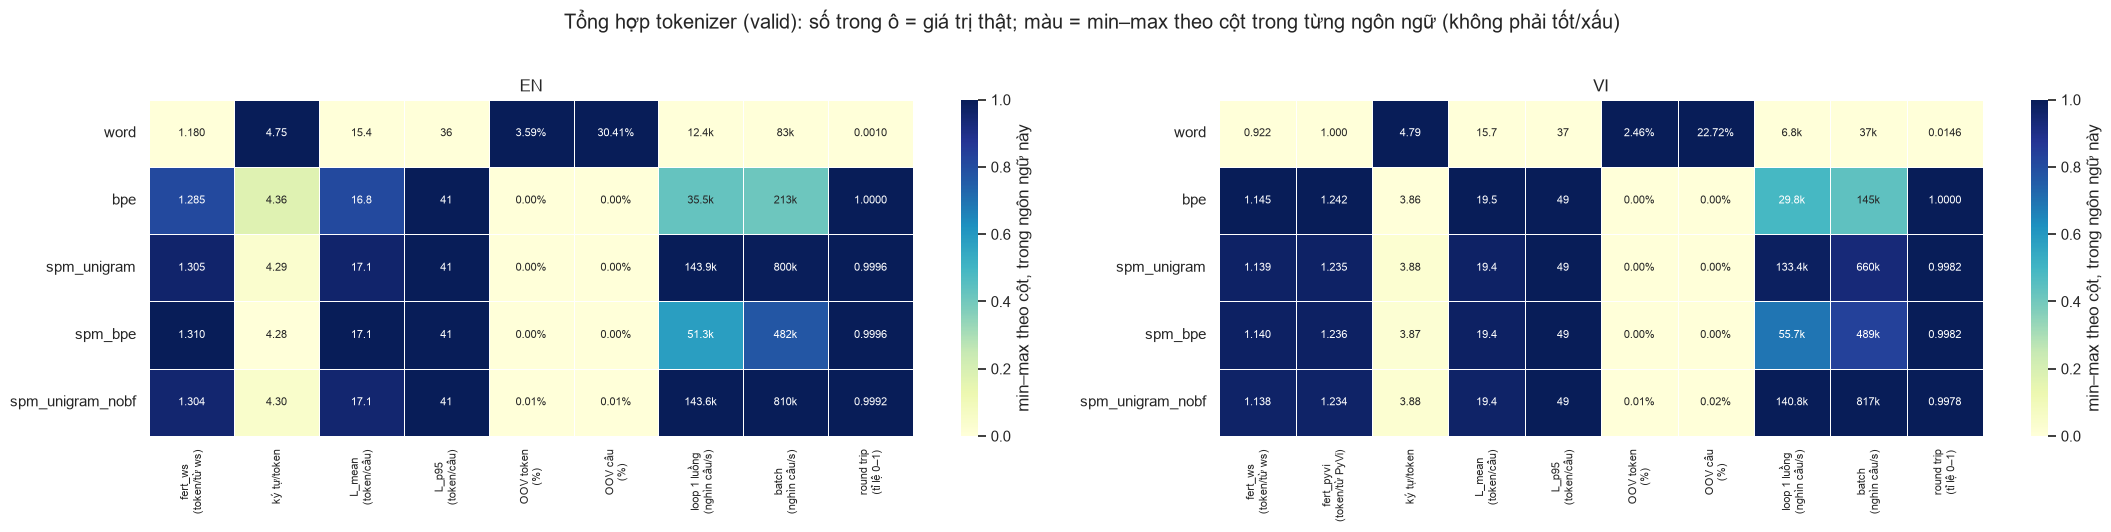

**Bảng tổng hợp (valid).** Lưu ý: OOV $=0$ của `bpe`/`spm_unigram`/`spm_bpe` là hệ quả của byte-level / `byte_fallback`, không phải kết quả thực nghiệm. `n_types` không so sánh được giữa các họ (word-level: type sau NLTK/PyVi; subword: từ tách khoảng trắng). `vocab_size` của word-level gồm cả 4 token đặc biệt. Tốc độ: `sps_loop` là đơn luồng (so sánh công bằng), `sps_batch` có mức song song khác nhau theo họ (xem mục 10).

| variant          | lang   |   vocab_size |   fert_ws |   fert_pyvi |   chars_per_token |   L_mean |   L_median |   L_p95 |   L_p99 |   L_max |   pct_gt64 |   pct_gt128 |   oov_token |   oov_type |   oov_sent |   sps_loop |   sps_batch |   rt_exact |
|:-----------------|:-------|-------------:|----------:|------------:|------------------:|---------:|-----------:|--------:|--------:|--------:|-----------:|------------:|------------:|-----------:|-----------:|-----------:|------------:|-----------:|
| word             | en     |        32000 |    1.1804 |    nan      |            4.7468 |  15.4446 |         12 |      36 |    53.1 |     223 |     0.4755 |      0.0248 |      0.0359 |     0.3273 |     0.3041 |   12375    |     83283.3 |     0.001  |
| bpe              | en     |        32000 |    1.2855 |    nan      |            4.3587 |  16.8198 |         13 |      41 |    61   |     284 |     0.8122 |      0.0495 |      0      |     0      |     0      |   35452.3  |    213452   |     1      |
| spm_unigram      | en     |        32000 |    1.3049 |    nan      |            4.2937 |  17.0745 |         13 |      41 |    61   |     281 |     0.842  |      0.0495 |      0      |     0      |     0      |  143866    |    800309   |     0.9996 |
| spm_bpe          | en     |        32000 |    1.3101 |    nan      |            4.2767 |  17.1423 |         13 |      41 |    62   |     281 |     0.8073 |      0.0495 |      0      |     0      |     0      |   51305.5  |    481881   |     0.9996 |
| spm_unigram_nobf | en     |        32000 |    1.3038 |    nan      |            4.2976 |  17.0591 |         13 |      41 |    61   |     281 |     0.8321 |      0.0495 |      0.0001 |     0.0002 |     0.0001 |  143585    |    809879   |     0.9992 |
| word             | vi     |        32000 |    0.9223 |      1      |            4.7886 |  15.6884 |         12 |      37 |    55   |     219 |     0.52   |      0.0297 |      0.0246 |     0.2955 |     0.2272 |    6783.51 |     37320.6 |     0.0146 |
| bpe              | vi     |        32000 |    1.1455 |      1.242  |            3.8556 |  19.4849 |         14 |      49 |    74   |     315 |     1.7186 |      0.109  |      0      |     0      |     0      |   29827.9  |    144792   |     1      |
| spm_unigram      | vi     |        32000 |    1.1388 |      1.2348 |            3.8782 |  19.3713 |         14 |      49 |    73   |     312 |     1.6641 |      0.109  |      0      |     0      |     0      |  133390    |    659832   |     0.9982 |
| spm_bpe          | vi     |        32000 |    1.1398 |      1.2358 |            3.8749 |  19.3879 |         14 |      49 |    73   |     308 |     1.6691 |      0.109  |      0      |     0      |     0      |   55700.3  |    488703   |     0.9982 |
| spm_unigram_nobf | vi     |        32000 |    1.1384 |      1.2344 |            3.8794 |  19.3651 |         14 |      49 |    73   |     312 |     1.6641 |      0.109  |      0.0001 |     0.0007 |     0.0002 |  140767    |    817330   |     0.9978 |

**Kiểm tra chéo trên test** (fertility, CPT, L, OOV):

| variant          | lang   |   fert_ws |   chars_per_token |   L_mean |   oov_token |   oov_type |   oov_sent |
|:-----------------|:-------|----------:|------------------:|---------:|------------:|-----------:|-----------:|
| word             | en     |    1.1809 |            4.7685 |  16.4746 |      0.0376 |     0.343  |     0.3293 |
| bpe              | en     |    1.289  |            4.3687 |  17.9823 |      0      |     0      |     0      |
| spm_unigram      | en     |    1.3076 |            4.3065 |  18.2421 |      0      |     0      |     0      |
| spm_bpe          | en     |    1.3142 |            4.285  |  18.3337 |      0      |     0      |     0      |
| spm_unigram_nobf | en     |    1.3067 |            4.3095 |  18.2296 |      0      |     0.0002 |     0.0003 |
| word             | vi     |    0.9197 |            4.8308 |  16.7813 |      0.0259 |     0.3112 |     0.241  |
| bpe              | vi     |    1.1439 |            3.8838 |  20.873  |      0      |     0      |     0      |
| spm_unigram      | vi     |    1.1374 |            3.9062 |  20.7531 |      0      |     0      |     0      |
| spm_bpe          | vi     |    1.1388 |            3.9014 |  20.7787 |      0      |     0      |     0      |
| spm_unigram_nobf | vi     |    1.1371 |            3.9071 |  20.7485 |      0      |     0.0002 |     0.0002 |

**Tỉ số độ dài $\rho=L_{vi}/L_{en}$:**

| variant          |     en |     vi |   rho_vi_en |
|:-----------------|-------:|-------:|------------:|
| word             | 15.445 | 15.688 |       1.016 |
| bpe              | 16.82  | 19.485 |       1.158 |
| spm_unigram      | 17.074 | 19.371 |       1.135 |
| spm_bpe          | 17.142 | 19.388 |       1.131 |
| spm_unigram_nobf | 17.059 | 19.365 |       1.135 |

In [23]:
spd = SPEED.pivot_table(index=['variant', 'lang'], columns='mode', values=['sent_per_s', 'tok_per_s'])
spd.columns = [f'{"sps" if a == "sent_per_s" else "tps"}_{b}' for a, b in spd.columns]
SUMMARY = (M_VALID.merge(spd.reset_index(), on=['variant', 'lang']).merge(RTDF[['variant', 'lang', 'rt_exact']], on=['variant', 'lang']))
SUMMARY['order'] = SUMMARY.variant.map(VARIANTS.index)
SUMMARY = SUMMARY.sort_values(['lang', 'order']).drop(columns='order').reset_index(drop=True)

# ---- kiểm tra hợp lệ
assert set(SUMMARY.family) == {'word', 'bpe', 'spm'} and (SUMMARY.groupby('family').lang.nunique() == 2).all()
assert len(SUMMARY) == len(VARIANTS) * len(LANGS)
assert SUMMARY.drop(columns='fert_pyvi').isna().sum().sum() == 0 and SUMMARY[SUMMARY.lang == 'vi'].fert_pyvi.notna().all()
assert SUMMARY.rt_exact.between(0, 1).all()
assert (SUMMARY[SUMMARY.variant == 'bpe'].n_unk == 0).all(), 'BPE có <unk>!'
if SAMPLE:
    assert (SUMMARY.vocab_size <= VOCAB_SIZE).all()
else:
    assert (SUMMARY.vocab_size == VOCAB_SIZE).all(), SUMMARY[['variant', 'lang', 'vocab_size']]
print('SPM byte_fallback n_unk:', SUMMARY[SUMMARY.variant.isin(['spm_unigram', 'spm_bpe'])].n_unk.tolist())
SUMMARY.round(6).to_csv(RES_DIR / 'summary.csv', index=False)
M_TEST.round(6).to_csv(RES_DIR / 'summary_test.csv', index=False)
SPEED.round(6).to_csv(RES_DIR / 'speed.csv', index=False); curve.round(6).to_csv(RES_DIR / 'word_oov_curve.csv', index=False)
OVL.round(6).to_csv(RES_DIR / 'vocab_overlap.csv', index=False); SWEEP.round(6).to_csv(RES_DIR / 'bpe_vocab_sweep.csv', index=False); RTDF.round(6).to_csv(RES_DIR / 'roundtrip.csv', index=False)

HCOLS = {   # cột -> (tên hiển thị kèm đơn vị, hàm định dạng giá trị thật)
    'fert_ws': ('fert_ws\n(token/từ ws)', lambda x: f'{x:.3f}'),
    'fert_pyvi': ('fert_pyvi\n(token/từ PyVi)', lambda x: f'{x:.3f}'),
    'chars_per_token': ('ký tự/token', lambda x: f'{x:.2f}'),
    'L_mean': ('L_mean\n(token/câu)', lambda x: f'{x:.1f}'),
    'L_p95': ('L_p95\n(token/câu)', lambda x: f'{x:.0f}'),
    'oov_token': ('OOV token\n(%)', lambda x: f'{100 * x:.2f}%'),
    'oov_sent': ('OOV câu\n(%)', lambda x: f'{100 * x:.2f}%'),
    'sps_loop': ('loop 1 luồng\n(nghìn câu/s)', lambda x: f'{x / 1e3:.1f}k'),
    'sps_batch': ('batch\n(nghìn câu/s)', lambda x: f'{x / 1e3:.0f}k'),
    'rt_exact': ('round trip\n(tỉ lệ 0–1)', lambda x: f'{x:.4f}'),
}
fig, axes = plt.subplots(1, 2, figsize=(22, 5.2))
for ax, l in zip(axes, LANGS):
    sub = SUMMARY[SUMMARY.lang == l].set_index('variant').loc[VARIANTS]
    cl = [c for c in HCOLS if sub[c].notna().all()]
    H = sub[cl].astype(float).copy()
    for c in ('sps_loop', 'sps_batch'): H[c] = np.log10(H[c])           # màu theo log10, nhãn là giá trị thật
    span = (H.max() - H.min()).replace(0, np.nan)
    Hn = ((H - H.min()) / span).fillna(0.5)
    lab = pd.DataFrame({c: [HCOLS[c][1](x) for x in sub[c]] for c in cl}, index=sub.index)
    sns.heatmap(Hn.rename(columns={c: HCOLS[c][0] for c in cl}), annot=lab.values, fmt='', cmap='YlGnBu', vmin=0, vmax=1,
                cbar_kws={'label': 'min–max theo cột, trong ngôn ngữ này'}, linewidths=.5, ax=ax, annot_kws={'fontsize': 8})
    ax.set_title(f'{l.upper()}'); ax.set_ylabel(''); ax.tick_params(axis='x', labelsize=8)
fig.suptitle('Tổng hợp tokenizer (valid): số trong ô = giá trị thật; màu = min–max theo cột trong từng ngôn ngữ (không phải tốt/xấu)', y=1.02)
savefig('summary_heatmap.png')

show = SUMMARY[['variant', 'lang', 'vocab_size', 'fert_ws', 'fert_pyvi', 'chars_per_token', 'L_mean', 'L_median', 'L_p95', 'L_p99', 'L_max', 'pct_gt64', 'pct_gt128', 'oov_token', 'oov_type', 'oov_sent', 'sps_loop', 'sps_batch', 'rt_exact']]
display(Markdown('**Bảng tổng hợp (valid).** Lưu ý: OOV $=0$ của `bpe`/`spm_unigram`/`spm_bpe` là hệ quả của byte-level / `byte_fallback`, không phải kết quả thực nghiệm. `n_types` không so sánh được giữa các họ (word-level: type sau NLTK/PyVi; subword: từ tách khoảng trắng). `vocab_size` của word-level gồm cả 4 token đặc biệt. Tốc độ: `sps_loop` là đơn luồng (so sánh công bằng), `sps_batch` có mức song song khác nhau theo họ (xem mục 10).'))
display(Markdown(show.round(4).to_markdown(index=False)))
display(Markdown('**Kiểm tra chéo trên test** (fertility, CPT, L, OOV):\n\n' + M_TEST[['variant', 'lang', 'fert_ws', 'chars_per_token', 'L_mean', 'oov_token', 'oov_type', 'oov_sent']].round(4).to_markdown(index=False)))
display(Markdown('**Tỉ số độ dài $\\rho=L_{vi}/L_{en}$:**\n\n' + ratio.round(3).to_markdown()))

## 14. Kết luận (sinh tự động từ các DataFrame kết quả, không gõ tay số liệu)

Ô code bên dưới dựng toàn bộ văn bản kết luận bằng f-string từ `SUMMARY`, `SPEED`, `curve`, `SWEEP`, `OVL`, `RTDF`, `JOINT` của *lần chạy này*, nên số liệu không thể lỗi thời so với bảng ở mục 13. Các câu định tính chỉ mô tả cấu trúc (so sánh, khoảng giá trị); mọi con số đều lấy từ kết quả.

In [24]:
S = SUMMARY.set_index(['variant', 'lang'])
SPD = SPEED.set_index(['variant', 'lang', 'mode']).sent_per_s
RTI = RTDF.set_index(['variant', 'lang'])
OV = OVL.set_index('variant')
JI = JOINT.set_index(['algo', 'vocab', 'lang'])
SUBW = ['bpe', 'spm_unigram', 'spm_bpe']
g = lambda v, l, c: S.loc[(v, l), c]
pc = lambda x, d=1: f'{100 * x:.{d}f}%'
def span(c, l, d=2, vs=SUBW):
    xs = [g(v, l, c) for v in vs]
    return f'{min(xs):.{d}f}–{max(xs):.{d}f}'
def rel_spread(c, l):
    xs = [g(v, l, c) for v in SUBW]
    return 100 * (max(xs) - min(xs)) / min(xs)
sp = lambda v, l, m: SPD[(v, l, m)]
k = lambda x: f'{x / 1e3:.0f}k'
def ratio_rng(num, den, m):
    r = [sp(num, l, m) / sp(den, l, m) for l in LANGS]
    return f'{min(r):.1f}–{max(r):.1f}'
N_RTn = int(RTDF.iloc[0][['exact', 'has_unk', 'spacing_only', 'other_normalization']].sum())
rho = lambda v: g(v, 'vi', 'L_mean') / g(v, 'en', 'L_mean')
sw = SWEEP.pivot(index='V', columns='lang', values='fert_ws')
cu = curve[curve.label == 'all'].set_index('lang')
sig = lambda x: 'tăng' if x > 0 else 'giảm'

P = []
P.append(rf"""**1. Độ dài chuỗi vs OOV.** Word-level: $L$ = {g('word','en','L_mean'):.1f} (EN) và {g('word','vi','L_mean'):.1f} (VI) token/câu, nhưng OOV EN {pc(g('word','en','oov_token'))} token / {pc(g('word','en','oov_type'))} type / {pc(g('word','en','oov_sent'))} câu có `<unk>`; VI {pc(g('word','vi','oov_token'))} token / {pc(g('word','vi','oov_type'))} type / {pc(g('word','vi','oov_sent'))} câu. Ba biến thể subword (`bpe`, `spm_unigram`, `spm_bpe`): EN $L$ = {span('L_mean','en',1)} (fertility {span('fert_ws','en',3)}), VI $L$ = {span('L_mean','vi',1)} (fertility theo âm tiết {span('fert_ws','vi',3)}, theo từ PyVi {span('fert_pyvi','vi',3)}). So với word-level, subword dài hơn {pc(min(g(v,'en','L_mean') for v in SUBW)/g('word','en','L_mean')-1,0)}–{pc(max(g(v,'en','L_mean') for v in SUBW)/g('word','en','L_mean')-1,0)} (EN) và {pc(min(g(v,'vi','L_mean') for v in SUBW)/g('word','vi','L_mean')-1,0)}–{pc(max(g(v,'vi','L_mean') for v in SUBW)/g('word','vi','L_mean')-1,0)} (VI). OOV subword $=0$ là **do cấu trúc** (byte-level / `byte_fallback`), không phải kết quả thực nghiệm. Với word-level, ngay cả giữ toàn bộ từ vựng train (EN {int(cu.loc['en','N']):,d}, VI {int(cu.loc['vi','N']):,d} mục) vẫn còn OOV token EN {pc(cu.loc['en','oov_token'],2)}, VI {pc(cu.loc['vi','oov_token'],2)} (mục 9.2).""")

P.append(rf"""**2. Mức chênh giữa ba biến thể subword.** Chênh fertility lớn nhất giữa chúng là {rel_spread('fert_ws','en'):.1f}% (EN) và {rel_spread('fert_ws','vi'):.1f}% (VI); chênh $L$ là {rel_spread('L_mean','en'):.1f}% (EN) và {rel_spread('L_mean','vi'):.1f}% (VI). Ký tự/token EN: bpe {g('bpe','en','chars_per_token'):.2f}, spm_unigram {g('spm_unigram','en','chars_per_token'):.2f}, spm_bpe {g('spm_bpe','en','chars_per_token'):.2f}; VI: bpe {g('bpe','vi','chars_per_token'):.3f}, spm_unigram {g('spm_unigram','vi','chars_per_token'):.3f}, spm_bpe {g('spm_bpe','vi','chars_per_token'):.3f}. `spm_unigram_nobf` (không byte_fallback) có OOV token EN {pc(g('spm_unigram_nobf','en','oov_token'),3)}, VI {pc(g('spm_unigram_nobf','vi','oov_token'),3)}; OOV câu EN {pc(g('spm_unigram_nobf','en','oov_sent'),3)}, VI {pc(g('spm_unigram_nobf','vi','oov_sent'),3)}.""")

P.append(rf"""**3. Tiếng Việt vs tiếng Anh.** Tỉ số $\rho=L_{{vi}}/L_{{en}}$: word-level {rho('word'):.2f}; bpe {rho('bpe'):.2f}, spm_unigram {rho('spm_unigram'):.2f}, spm_bpe {rho('spm_bpe'):.2f}. Với `spm_unigram`: câu vượt 64 token VI {g('spm_unigram','vi','pct_gt64'):.2f}% so với EN {g('spm_unigram','en','pct_gt64'):.2f}%; vượt 128 token VI {g('spm_unigram','vi','pct_gt128'):.3f}% so với EN {g('spm_unigram','en','pct_gt128'):.3f}%; $L_{{max}}$ VI = {int(g('spm_unigram','vi','L_max'))}, EN = {int(g('spm_unigram','en','L_max'))}.""")

P.append(rf"""**4. Tốc độ (so sánh công bằng = vòng lặp đơn luồng).** Mức song song mỗi họ khác nhau: {PAR_NOTE}. **Tóm lại:** chỉ số loop (1 luồng) mới so sánh công bằng giữa các họ; số batch bị lệch bởi mức song song khác nhau. Loop (câu/s, EN / VI): word {k(sp('word','en','loop'))} / {k(sp('word','vi','loop'))}; bpe {k(sp('bpe','en','loop'))} / {k(sp('bpe','vi','loop'))}; spm_unigram {k(sp('spm_unigram','en','loop'))} / {k(sp('spm_unigram','vi','loop'))}; spm_bpe {k(sp('spm_bpe','en','loop'))} / {k(sp('spm_bpe','vi','loop'))}. **Tỉ số loop so với word-level** (min–max của EN, VI): SPM-unigram {ratio_rng('spm_unigram','word','loop')} lần, SPM-BPE {ratio_rng('spm_bpe','word','loop')} lần, HF BPE {ratio_rng('bpe','word','loop')} lần. Batch (câu/s, EN / VI): word {k(sp('word','en','batch'))} / {k(sp('word','vi','batch'))}; bpe {k(sp('bpe','en','batch'))} / {k(sp('bpe','vi','batch'))}; spm_unigram {k(sp('spm_unigram','en','batch'))} / {k(sp('spm_unigram','vi','batch'))}; spm_bpe {k(sp('spm_bpe','en','batch'))} / {k(sp('spm_bpe','vi','batch'))} (tỉ số batch so với word-level: SPM-unigram {ratio_rng('spm_unigram','word','batch')} lần, HF BPE {ratio_rng('bpe','word','batch')} lần, nhưng lệch vì song song hóa khác nhau).""")

P.append(rf"""**5. Round trip** (trên {N_RTn:,d} câu valid). bpe: EN {RTI.loc[('bpe','en'),'rt_exact']:.4f}, VI {RTI.loc[('bpe','vi'),'rt_exact']:.4f}. SentencePiece: unigram EN {RTI.loc[('spm_unigram','en'),'rt_exact']:.4f} / VI {RTI.loc[('spm_unigram','vi'),'rt_exact']:.4f}; bpe EN {RTI.loc[('spm_bpe','en'),'rt_exact']:.4f} / VI {RTI.loc[('spm_bpe','vi'),'rt_exact']:.4f}; unigram_nobf EN {RTI.loc[('spm_unigram_nobf','en'),'rt_exact']:.4f} / VI {RTI.loc[('spm_unigram_nobf','vi'),'rt_exact']:.4f} (phần lệch do chuẩn hóa NFKC mặc định, `<unk>` ở nobf; chi tiết mục 11). Word-level: EN {RTI.loc[('word','en'),'rt_exact']:.4f}, VI {RTI.loc[('word','vi'),'rt_exact']:.4f}; trong đó chỉ khác khoảng trắng EN {int(RTI.loc[('word','en'),'spacing_only'])}/{N_RTn}, VI {int(RTI.loc[('word','vi'),'spacing_only'])}/{N_RTn}; có `<unk>` EN {int(RTI.loc[('word','en'),'has_unk'])}, VI {int(RTI.loc[('word','vi'),'has_unk'])}; chuẩn hóa khác EN {int(RTI.loc[('word','en'),'other_normalization'])}, VI {int(RTI.loc[('word','vi'),'other_normalization'])}. Detokenizer chỉ cứu được phần khoảng trắng, không cứu được `<unk>`.""")

P.append(rf"""**6. Từ vựng chung EN/VI (mục 12.3).** Số mục chung / Jaccard: bpe {int(OV.loc['bpe','shared']):,d} / {OV.loc['bpe','jaccard']:.2f} ({OV.loc['bpe','shared_pct_of_en']:.0f}% vocab EN); spm_unigram {int(OV.loc['spm_unigram','shared']):,d} / {OV.loc['spm_unigram','jaccard']:.2f} ({OV.loc['spm_unigram','shared_pct_of_en']:.0f}%); spm_bpe {int(OV.loc['spm_bpe','shared']):,d} / {OV.loc['spm_bpe','jaccard']:.2f}; word {int(OV.loc['word','shared']):,d} / {OV.loc['word','jaccard']:.2f}.""")

jt = '; '.join(f"{a} {l.upper()}: {JI.loc[(a,'separate',l),'fert_ws']:.3f} → {JI.loc[(a,'joint',l),'fert_ws']:.3f} ({JI.loc[(a,'joint',l),'fert_vs_separate_pct']:+.1f}%), $L$ {JI.loc[(a,'separate',l),'L_mean']:.1f} → {JI.loc[(a,'joint',l),'L_mean']:.1f}" for a in ['spm_unigram', 'bpe'] for l in LANGS)
P.append(rf"""**7. Joint vs separate (mục 12.7, chỉ fertility/độ dài).** Fertility separate → joint (V = {VOCAB_SIZE:,d} cho bộ chung, {VOCAB_SIZE:,d} mỗi ngôn ngữ cho bộ riêng): {jt}. Thay đổi fertility lớn nhất của vocab chung so với riêng là {JOINT.fert_vs_separate_pct.abs().max():.1f}% (ở {JOINT.loc[JOINT.fert_vs_separate_pct.abs().idxmax(), 'key']}).""")

P.append(rf"""**8. Kích thước vocab BPE (mục 12.5).** Fertility EN: {' → '.join(f"{sw.loc[V,'en']:.3f}" for V in SWEEP_SIZES)}; VI: {' → '.join(f"{sw.loc[V,'vi']:.3f}" for V in SWEEP_SIZES)} (V = {' / '.join(f'{V:,d}' for V in SWEEP_SIZES)}). Mức giảm khi nhân đôi V cuối cùng: EN {pc(1 - sw.loc[SWEEP_SIZES[-1],'en'] / sw.loc[SWEEP_SIZES[-2],'en'])}, VI {pc(1 - sw.loc[SWEEP_SIZES[-1],'vi'] / sw.loc[SWEEP_SIZES[-2],'vi'])}.""")

P.append(rf"""**Khuyến nghị (dựa trên metric tokenizer, không phải BLEU).**
- Subword (SentencePiece unigram hoặc byte-level BPE) thay vì word-level: chuỗi chỉ dài hơn mức nêu ở đoạn 1, không có `<unk>` (do cấu trúc), nhanh hơn word-level {ratio_rng('spm_unigram','word','loop')} lần ở chế độ loop đơn luồng (SPM-unigram) và không cần tiền tách từ PyVi. Nếu cần khôi phục 100% văn bản gốc, tắt chuẩn hóa NFKC (`normalization_rule_name=identity`).
- **Joint vs separate là một giả thuyết**, chưa phải kết luận: độ chồng lấn từ vựng thấp ({min(OV.loc[v,'shared_pct_of_en'] for v in SUBW):.0f}–{max(OV.loc[v,'shared_pct_of_en'] for v in SUBW):.0f}% vocab EN) gợi ý lợi ích chia sẻ hạn chế, và thử nghiệm 12.7 cho thấy vocab chung {sig(JOINT[JOINT.vocab=='joint'].fert_vs_separate_pct.mean())} fertility trung bình {JOINT[JOINT.vocab=='joint'].fert_vs_separate_pct.mean():+.1f}% so với vocab riêng. Chỉ khi cần tie embedding / mô hình đa ngôn ngữ mới đáng cân nhắc vocab chung, và phải kiểm tra bằng BLEU.
- **Kích thước:** xem đoạn 8 ở trên; chọn V theo mức giảm fertility biên so với chi phí embedding/softmax tuyến tính theo V.""")

P.append(rf"""**Hạn chế.**
- Không đo chất lượng dịch (BLEU/chrF); mọi so sánh chỉ dựa trên fertility, độ dài, OOV, tốc độ, round trip. Việc chọn tokenizer theo fertility *không* chứng minh chất lượng dịch tốt hơn.
- Một seed duy nhất; không có khoảng tin cậy.
- Tokenizer chỉ huấn luyện trên {N_TRAIN_SENT:,d} câu mẫu mỗi ngôn ngữ trong tổng {N_ALL:,d} cặp câu train (~{100 * N_TRAIN_SENT / N_ALL:.0f}%).
- OOV subword $=0$ là do cấu trúc; `n_types` không so sánh được giữa các họ; vocab word-level tính cả specials.
- Tốc độ đo trên một máy ({N_PROC} CPU), trung vị 3 lượt; mức song song khác nhau theo họ nên chỉ số loop mới công bằng.
- Joint vs separate chỉ thử với một cấu hình (V cố định, unigram và BPE), chỉ trên fertility/độ dài; quét V chỉ làm cho BPE.
- Round trip đo trên {N_RTn:,d} câu, không phải toàn bộ valid.""")
display(Markdown('\n\n'.join(P)))


**1. Độ dài chuỗi vs OOV.** Word-level: $L$ = 15.4 (EN) và 15.7 (VI) token/câu, nhưng OOV EN 3.6% token / 32.7% type / 30.4% câu có `<unk>`; VI 2.5% token / 29.6% type / 22.7% câu. Ba biến thể subword (`bpe`, `spm_unigram`, `spm_bpe`): EN $L$ = 16.8–17.1 (fertility 1.285–1.310), VI $L$ = 19.4–19.5 (fertility theo âm tiết 1.139–1.145, theo từ PyVi 1.235–1.242). So với word-level, subword dài hơn 9%–11% (EN) và 23%–24% (VI). OOV subword $=0$ là **do cấu trúc** (byte-level / `byte_fallback`), không phải kết quả thực nghiệm. Với word-level, ngay cả giữ toàn bộ từ vựng train (EN 340,778, VI 308,721 mục) vẫn còn OOV token EN 1.00%, VI 1.07% (mục 9.2).

**2. Mức chênh giữa ba biến thể subword.** Chênh fertility lớn nhất giữa chúng là 1.9% (EN) và 0.6% (VI); chênh $L$ là 1.9% (EN) và 0.6% (VI). Ký tự/token EN: bpe 4.36, spm_unigram 4.29, spm_bpe 4.28; VI: bpe 3.856, spm_unigram 3.878, spm_bpe 3.875. `spm_unigram_nobf` (không byte_fallback) có OOV token EN 0.011%, VI 0.006%; OOV câu EN 0.015%, VI 0.020%.

**3. Tiếng Việt vs tiếng Anh.** Tỉ số $\rho=L_{vi}/L_{en}$: word-level 1.02; bpe 1.16, spm_unigram 1.13, spm_bpe 1.13. Với `spm_unigram`: câu vượt 64 token VI 1.66% so với EN 0.84%; vượt 128 token VI 0.109% so với EN 0.050%; $L_{max}$ VI = 312, EN = 281.

**4. Tốc độ (so sánh công bằng = vòng lặp đơn luồng).** Mức song song mỗi họ khác nhau: HF encode_batch: Rust đa luồng; SPM: num_threads=16 (=min(16,cpu=20)); word-level: Pool 12 tiến trình (spawn). **Tóm lại:** chỉ số loop (1 luồng) mới so sánh công bằng giữa các họ; số batch bị lệch bởi mức song song khác nhau. Loop (câu/s, EN / VI): word 12k / 7k; bpe 35k / 30k; spm_unigram 144k / 133k; spm_bpe 51k / 56k. **Tỉ số loop so với word-level** (min–max của EN, VI): SPM-unigram 11.6–19.7 lần, SPM-BPE 4.1–8.2 lần, HF BPE 2.9–4.4 lần. Batch (câu/s, EN / VI): word 83k / 37k; bpe 213k / 145k; spm_unigram 800k / 660k; spm_bpe 482k / 489k (tỉ số batch so với word-level: SPM-unigram 9.6–17.7 lần, HF BPE 2.6–3.9 lần, nhưng lệch vì song song hóa khác nhau).

**5. Round trip** (trên 5,000 câu valid). bpe: EN 1.0000, VI 1.0000. SentencePiece: unigram EN 0.9996 / VI 0.9982; bpe EN 0.9996 / VI 0.9982; unigram_nobf EN 0.9992 / VI 0.9978 (phần lệch do chuẩn hóa NFKC mặc định, `<unk>` ở nobf; chi tiết mục 11). Word-level: EN 0.0010, VI 0.0146; trong đó chỉ khác khoảng trắng EN 3333/5000, VI 3833/5000; có `<unk>` EN 1557, VI 1094; chuẩn hóa khác EN 105, VI 0. Detokenizer chỉ cứu được phần khoảng trắng, không cứu được `<unk>`.

**6. Từ vựng chung EN/VI (mục 12.3).** Số mục chung / Jaccard: bpe 11,059 / 0.21 (35% vocab EN); spm_unigram 13,366 / 0.26 (42%); spm_bpe 12,968 / 0.25; word 7,487 / 0.13.

**7. Joint vs separate (mục 12.7, chỉ fertility/độ dài).** Fertility separate → joint (V = 32,000 cho bộ chung, 32,000 mỗi ngôn ngữ cho bộ riêng): spm_unigram EN: 1.305 → 1.327 (+1.7%), $L$ 17.1 → 17.4; spm_unigram VI: 1.139 → 1.153 (+1.2%), $L$ 19.4 → 19.6; bpe EN: 1.285 → 1.306 (+1.6%), $L$ 16.8 → 17.1; bpe VI: 1.145 → 1.160 (+1.3%), $L$ 19.5 → 19.7. Thay đổi fertility lớn nhất của vocab chung so với riêng là 1.7% (ở spm_unigram / EN).

**8. Kích thước vocab BPE (mục 12.5).** Fertility EN: 1.478 → 1.360 → 1.285; VI: 1.194 → 1.163 → 1.145 (V = 8,000 / 16,000 / 32,000). Mức giảm khi nhân đôi V cuối cùng: EN 5.5%, VI 1.5%.

**Khuyến nghị (dựa trên metric tokenizer, không phải BLEU).**
- Subword (SentencePiece unigram hoặc byte-level BPE) thay vì word-level: chuỗi chỉ dài hơn mức nêu ở đoạn 1, không có `<unk>` (do cấu trúc), nhanh hơn word-level 11.6–19.7 lần ở chế độ loop đơn luồng (SPM-unigram) và không cần tiền tách từ PyVi. Nếu cần khôi phục 100% văn bản gốc, tắt chuẩn hóa NFKC (`normalization_rule_name=identity`).
- **Joint vs separate là một giả thuyết**, chưa phải kết luận: độ chồng lấn từ vựng thấp (35–42% vocab EN) gợi ý lợi ích chia sẻ hạn chế, và thử nghiệm 12.7 cho thấy vocab chung tăng fertility trung bình +1.4% so với vocab riêng. Chỉ khi cần tie embedding / mô hình đa ngôn ngữ mới đáng cân nhắc vocab chung, và phải kiểm tra bằng BLEU.
- **Kích thước:** xem đoạn 8 ở trên; chọn V theo mức giảm fertility biên so với chi phí embedding/softmax tuyến tính theo V.

**Hạn chế.**
- Không đo chất lượng dịch (BLEU/chrF); mọi so sánh chỉ dựa trên fertility, độ dài, OOV, tốc độ, round trip. Việc chọn tokenizer theo fertility *không* chứng minh chất lượng dịch tốt hơn.
- Một seed duy nhất; không có khoảng tin cậy.
- Tokenizer chỉ huấn luyện trên 1,000,000 câu mẫu mỗi ngôn ngữ trong tổng 5,247,518 cặp câu train (~19%).
- OOV subword $=0$ là do cấu trúc; `n_types` không so sánh được giữa các họ; vocab word-level tính cả specials.
- Tốc độ đo trên một máy (20 CPU), trung vị 3 lượt; mức song song khác nhau theo họ nên chỉ số loop mới công bằng.
- Joint vs separate chỉ thử với một cấu hình (V cố định, unigram và BPE), chỉ trên fertility/độ dài; quét V chỉ làm cho BPE.
- Round trip đo trên 5,000 câu, không phải toàn bộ valid.

In [25]:
POOL.close(); POOL.join()
(TOK_DIR / 'train_times.json').write_text(json.dumps(TIMES, indent=1))
print(f'Tổng thời gian chạy notebook: {(time.perf_counter() - T0) / 60:.1f} phút | SAMPLE={SAMPLE}')
print('Thời gian huấn luyện (s):', {k: round(v) for k, v in TIMES.items()})

Tổng thời gian chạy notebook: 13.6 phút | SAMPLE=False
Thời gian huấn luyện (s): {'train_word_en': 18, 'train_word_vi': 27, 'train_bpe_en_8000': 6, 'train_bpe_en_16000': 7, 'train_bpe_en_32000': 7, 'train_bpe_vi_8000': 6, 'train_bpe_vi_16000': 7, 'train_bpe_vi_32000': 8, 'train_spm_unigram_en': 105, 'train_spm_unigram_vi': 104, 'train_spm_bpe_en': 10, 'train_spm_bpe_vi': 10, 'train_spm_unigram_nobf_en': 105, 'train_spm_unigram_nobf_vi': 104, 'train_joint_spm_unigram': 203, 'train_joint_bpe': 10}
